In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import joblib
import gc

In [2]:
print("===== LOADING TRAIN DATASET =====")

df_train = pd.read_parquet(
    "train_historical_features.parquet"
)

print("Train shape:", df_train.shape)

print("\nFraud distribution:")
print(df_train["isFraud"].value_counts())

print("\nMemory usage:")
print(
    f"{df_train.memory_usage(deep=True).sum() / (1024**3):.2f} GB"
)

===== LOADING TRAIN DATASET =====
Train shape: (6082007, 35)

Fraud distribution:
isFraud
0    6076226
1       5781
Name: count, dtype: int64

Memory usage:
2.08 GB


In [3]:
print("===== TRAIN DATASET INSPECTION =====")

print("\nShape:")
print(df_train.shape)

print("\nColumns:")
for i, col in enumerate(df_train.columns, start=1):
    print(f"{i:02d}. {col}")

print("\nData Types:")
print(df_train.dtypes)

print("\nMemory Usage:")
print(f"{df_train.memory_usage(deep=True).sum() / (1024**3):.2f} GB")

===== TRAIN DATASET INSPECTION =====

Shape:
(6082007, 35)

Columns:
01. step
02. amount
03. nameOrig
04. oldbalanceOrg
05. newbalanceOrig
06. nameDest
07. oldbalanceDest
08. newbalanceDest
09. isFraud
10. isFlaggedFraud
11. origin_balance_error
12. abs_origin_balance_error
13. amount_to_origin_ratio
14. sender_balance_depleted
15. destination_balance_depleted
16. origin_balance_zero
17. hour_of_day
18. day_of_week
19. is_weekend
20. sender_balance_change
21. receiver_balance_change
22. receiver_amount_difference
23. type_CASH_IN
24. type_CASH_OUT
25. type_DEBIT
26. type_PAYMENT
27. type_TRANSFER
28. sender_past_transaction_count
29. sender_past_total_amount
30. sender_past_avg_amount
31. sender_past_unique_receivers
32. receiver_past_transaction_count
33. receiver_past_total_amount
34. receiver_past_avg_amount
35. receiver_past_unique_senders

Data Types:
step                                 int64
amount                             float64
nameOrig                            object
ol

In [4]:
print("===== DEFINING ML FEATURES =====")

target_column = "isFraud"

identifier_columns = [
    "nameOrig",
    "nameDest"
]

feature_columns = [
    col for col in df_train.columns
    if col not in [target_column] + identifier_columns
]

print("Target:", target_column)
print("Excluded identifiers:", identifier_columns)

print("\nNumber of ML features:", len(feature_columns))

print("\nML Features:")
for i, col in enumerate(feature_columns, start=1):
    print(f"{i:02d}. {col}")

print("\nTarget distribution:")
print(df_train[target_column].value_counts())

===== DEFINING ML FEATURES =====
Target: isFraud
Excluded identifiers: ['nameOrig', 'nameDest']

Number of ML features: 32

ML Features:
01. step
02. amount
03. oldbalanceOrg
04. newbalanceOrig
05. oldbalanceDest
06. newbalanceDest
07. isFlaggedFraud
08. origin_balance_error
09. abs_origin_balance_error
10. amount_to_origin_ratio
11. sender_balance_depleted
12. destination_balance_depleted
13. origin_balance_zero
14. hour_of_day
15. day_of_week
16. is_weekend
17. sender_balance_change
18. receiver_balance_change
19. receiver_amount_difference
20. type_CASH_IN
21. type_CASH_OUT
22. type_DEBIT
23. type_PAYMENT
24. type_TRANSFER
25. sender_past_transaction_count
26. sender_past_total_amount
27. sender_past_avg_amount
28. sender_past_unique_receivers
29. receiver_past_transaction_count
30. receiver_past_total_amount
31. receiver_past_avg_amount
32. receiver_past_unique_senders

Target distribution:
isFraud
0    6076226
1       5781
Name: count, dtype: int64


In [5]:
print("===== CLASS IMBALANCE ANALYSIS =====")

fraud_count = (df_train["isFraud"] == 1).sum()
nonfraud_count = (df_train["isFraud"] == 0).sum()
total_transactions = len(df_train)

fraud_percentage = (fraud_count / total_transactions) * 100
nonfraud_percentage = (nonfraud_count / total_transactions) * 100
imbalance_ratio = nonfraud_count / fraud_count

print(f"Total transactions : {total_transactions:,}")
print(f"Fraud transactions : {fraud_count:,}")
print(f"Non-fraud          : {nonfraud_count:,}")

print(f"\nFraud percentage   : {fraud_percentage:.4f}%")
print(f"Non-fraud percentage: {nonfraud_percentage:.4f}%")
print(f"Imbalance ratio    : 1 fraud : {imbalance_ratio:.1f} non-fraud")

===== CLASS IMBALANCE ANALYSIS =====
Total transactions : 6,082,007
Fraud transactions : 5,781
Non-fraud          : 6,076,226

Fraud percentage   : 0.0951%
Non-fraud percentage: 99.9049%
Imbalance ratio    : 1 fraud : 1051.1 non-fraud


In [6]:
print("===== CREATING BALANCED TRAINING SAMPLE =====")

fraud_data = df_train[df_train["isFraud"] == 1]

nonfraud_data = df_train[df_train["isFraud"] == 0]

nonfraud_sample = nonfraud_data.sample(
    n=len(fraud_data) * 5,
    random_state=42
)

df_train_sample = pd.concat(
    [fraud_data, nonfraud_sample],
    ignore_index=True
)

df_train_sample = df_train_sample.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Original training shape :", df_train.shape)
print("Sampled training shape  :", df_train_sample.shape)

print("\nSampled fraud distribution:")
print(df_train_sample["isFraud"].value_counts())

print("\nFraud percentage:")
print(
    f"{(df_train_sample['isFraud'].mean() * 100):.2f}%"
)

===== CREATING BALANCED TRAINING SAMPLE =====
Original training shape : (6082007, 35)
Sampled training shape  : (34686, 35)

Sampled fraud distribution:
isFraud
0    28905
1     5781
Name: count, dtype: int64

Fraud percentage:
16.67%


In [7]:
print("===== PREPARING TRAINING FEATURES AND TARGET =====")

X_train = df_train_sample[feature_columns].copy()

y_train = df_train_sample[target_column].copy()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nTarget distribution:")
print(y_train.value_counts())

print("\nFeature data types:")
print(X_train.dtypes.value_counts())

===== PREPARING TRAINING FEATURES AND TARGET =====
X_train shape: (34686, 32)
y_train shape: (34686,)

Target distribution:
isFraud
0    28905
1     5781
Name: count, dtype: int64

Feature data types:
float64    20
int64       8
int32       4
Name: count, dtype: int64


In [8]:
print("===== CHECKING MISSING AND INFINITE VALUES =====")

missing_values = X_train.isnull().sum().sum()

infinite_values = np.isinf(
    X_train.select_dtypes(include=[np.number])
).sum().sum()

print("Total missing values :", missing_values)
print("Total infinite values:", infinite_values)

if missing_values == 0 and infinite_values == 0:
    print("\nData quality check: PASSED")
else:
    print("\nData quality check: FAILED")

===== CHECKING MISSING AND INFINITE VALUES =====
Total missing values : 0
Total infinite values: 0

Data quality check: PASSED


In [9]:
print("===== CREATING FEATURE SCALER =====")

scaler = StandardScaler()

scaler.fit(X_train)

print("Scaler fitted successfully.")

print("\nNumber of features:", len(scaler.mean_))
print("Number of scale values:", len(scaler.scale_))

===== CREATING FEATURE SCALER =====
Scaler fitted successfully.

Number of features: 32
Number of scale values: 32


In [10]:
print("===== SCALING TRAINING FEATURES =====")

X_train_scaled = scaler.transform(X_train)

print("Scaled training shape:", X_train_scaled.shape)

print("\nScaled data type:")
print(X_train_scaled.dtype)

print("\nScaling completed successfully.")

===== SCALING TRAINING FEATURES =====
Scaled training shape: (34686, 32)

Scaled data type:
float64

Scaling completed successfully.


In [11]:
print("===== LOADING VALIDATION DATASET =====")

df_val = pd.read_parquet(
    "validation_historical_features.parquet"
)

print("Validation shape:", df_val.shape)

print("\nFraud distribution:")
print(df_val["isFraud"].value_counts())

print("\nMemory usage:")
print(
    f"{df_val.memory_usage(deep=True).sum() / (1024**3):.2f} GB"
)

===== LOADING VALIDATION DATASET =====
Validation shape: (191147, 35)

Fraud distribution:
isFraud
0    189967
1      1180
Name: count, dtype: int64

Memory usage:
0.07 GB


In [12]:
print("===== PREPARING VALIDATION FEATURES AND TARGET =====")

X_val = df_val[feature_columns].copy()

y_val = df_val[target_column].copy()

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("\nTarget distribution:")
print(y_val.value_counts())

===== PREPARING VALIDATION FEATURES AND TARGET =====
X_val shape: (191147, 32)
y_val shape: (191147,)

Target distribution:
isFraud
0    189967
1      1180
Name: count, dtype: int64


In [13]:
print("===== SCALING VALIDATION FEATURES =====")

X_val_scaled = scaler.transform(X_val)

print("Scaled validation shape:", X_val_scaled.shape)
print("Scaling completed successfully.")

===== SCALING VALIDATION FEATURES =====
Scaled validation shape: (191147, 32)
Scaling completed successfully.


In [14]:
print("===== CHECKING SCALED VALIDATION DATA =====")

missing_scaled_values = np.isnan(X_val_scaled).sum()

infinite_scaled_values = np.isinf(X_val_scaled).sum()

print("Total NaN values :", missing_scaled_values)
print("Total infinite values:", infinite_scaled_values)

if missing_scaled_values == 0 and infinite_scaled_values == 0:
    print("\nScaled validation data check: PASSED")
else:
    print("\nScaled validation data check: FAILED")

===== CHECKING SCALED VALIDATION DATA =====
Total NaN values : 0
Total infinite values: 0

Scaled validation data check: PASSED


In [15]:
print("===== CLEANING TEMPORARY VALIDATION OBJECTS =====")

del X_val
gc.collect()

print("Temporary validation feature copy removed.")
print("X_val_scaled and y_val are still available.")

===== CLEANING TEMPORARY VALIDATION OBJECTS =====
Temporary validation feature copy removed.
X_val_scaled and y_val are still available.


In [16]:
print("===== LOADING TEST DATASET =====")

df_test = pd.read_parquet(
    "test_historical_features.parquet"
)

print("Test shape:", df_test.shape)

print("\nFraud distribution:")
print(df_test["isFraud"].value_counts())

print("\nMemory usage:")
print(
    f"{df_test.memory_usage(deep=True).sum() / (1024**3):.2f} GB"
)

===== LOADING TEST DATASET =====
Test shape: (89466, 35)

Fraud distribution:
isFraud
0    88214
1     1252
Name: count, dtype: int64

Memory usage:
0.03 GB


In [17]:
print("===== PREPARING TEST FEATURES AND TARGET =====")

X_test = df_test[feature_columns].copy()

y_test = df_test[target_column].copy()

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTarget distribution:")
print(y_test.value_counts())

print("\nFeature data types:")
print(X_test.dtypes.value_counts())

===== PREPARING TEST FEATURES AND TARGET =====
X_test shape: (89466, 32)
y_test shape: (89466,)

Target distribution:
isFraud
0    88214
1     1252
Name: count, dtype: int64

Feature data types:
float64    20
int64       8
int32       4
Name: count, dtype: int64


In [18]:
print("===== CHECKING TEST MISSING AND INFINITE VALUES =====")

missing_values_test = X_test.isnull().sum().sum()

infinite_values_test = np.isinf(
    X_test.select_dtypes(include=[np.number])
).sum().sum()

print("Total missing values :", missing_values_test)
print("Total infinite values:", infinite_values_test)

if missing_values_test == 0 and infinite_values_test == 0:
    print("\nTest data quality check: PASSED")
else:
    print("\nTest data quality check: FAILED")

===== CHECKING TEST MISSING AND INFINITE VALUES =====
Total missing values : 0
Total infinite values: 0

Test data quality check: PASSED


In [19]:
print("===== SCALING TEST FEATURES =====")

X_test_scaled = scaler.transform(X_test)

print("Scaled test shape:", X_test_scaled.shape)

print("\nScaled data type:")
print(X_test_scaled.dtype)

print("\nScaling completed successfully.")

===== SCALING TEST FEATURES =====
Scaled test shape: (89466, 32)

Scaled data type:
float64

Scaling completed successfully.


In [20]:
print("===== CHECKING SCALED TEST DATA =====")

missing_scaled_test = np.isnan(X_test_scaled).sum()

infinite_scaled_test = np.isinf(X_test_scaled).sum()

print("Total NaN values :", missing_scaled_test)
print("Total infinite values:", infinite_scaled_test)

if missing_scaled_test == 0 and infinite_scaled_test == 0:
    print("\nScaled test data check: PASSED")
else:
    print("\nScaled test data check: FAILED")

===== CHECKING SCALED TEST DATA =====
Total NaN values : 0
Total infinite values: 0

Scaled test data check: PASSED


In [21]:
print("===== SAVING PREPROCESSING SCALER =====")

scaler_path = "fraud_detection_scaler.pkl"

joblib.dump(
    scaler,
    scaler_path
)

print(f"Scaler saved successfully: {scaler_path}")

===== SAVING PREPROCESSING SCALER =====
Scaler saved successfully: fraud_detection_scaler.pkl


In [22]:
print("===== SAVING ML FEATURE LIST =====")

feature_columns_path = "fraud_detection_feature_columns.pkl"

joblib.dump(
    feature_columns,
    feature_columns_path
)

print(f"Feature list saved successfully: {feature_columns_path}")
print("Number of ML features:", len(feature_columns))

===== SAVING ML FEATURE LIST =====
Feature list saved successfully: fraud_detection_feature_columns.pkl
Number of ML features: 32


In [23]:
print("===== CLEANING UNUSED DATAFRAMES =====")

del df_train
del df_train_sample
del df_val
del df_test
del X_test

gc.collect()

print("Unused DataFrames removed successfully.")
print("Scaled train, validation, and test data are still available.")

===== CLEANING UNUSED DATAFRAMES =====
Unused DataFrames removed successfully.
Scaled train, validation, and test data are still available.


In [24]:
from sklearn.linear_model import LogisticRegression

print("===== TRAINING LOGISTIC REGRESSION =====")

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression training completed successfully.")

===== TRAINING LOGISTIC REGRESSION =====
Logistic Regression training completed successfully.


In [25]:
print("===== GENERATING LOGISTIC REGRESSION VALIDATION SCORES =====")

y_val_proba_logistic = logistic_model.predict_proba(
    X_val_scaled
)[:, 1]

print("Validation probability shape:", y_val_proba_logistic.shape)

print("\nMinimum probability:", y_val_proba_logistic.min())
print("Maximum probability:", y_val_proba_logistic.max())

print("\nProbability generation completed successfully.")

===== GENERATING LOGISTIC REGRESSION VALIDATION SCORES =====
Validation probability shape: (191147,)

Minimum probability: 2.3327456778783556e-219
Maximum probability: 1.0

Probability generation completed successfully.


In [26]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

print("===== EVALUATING LOGISTIC REGRESSION =====")

threshold = 0.50

y_val_pred_logistic = (
    y_val_proba_logistic >= threshold
).astype(int)

precision_logistic = precision_score(
    y_val,
    y_val_pred_logistic,
    zero_division=0
)

recall_logistic = recall_score(
    y_val,
    y_val_pred_logistic,
    zero_division=0
)

f1_logistic = f1_score(
    y_val,
    y_val_pred_logistic,
    zero_division=0
)

pr_auc_logistic = average_precision_score(
    y_val,
    y_val_proba_logistic
)

roc_auc_logistic = roc_auc_score(
    y_val,
    y_val_proba_logistic
)

confusion_logistic = confusion_matrix(
    y_val,
    y_val_pred_logistic
)

tn_logistic, fp_logistic, fn_logistic, tp_logistic = (
    confusion_logistic.ravel()
)

print(f"Precision : {precision_logistic:.6f}")
print(f"Recall    : {recall_logistic:.6f}")
print(f"F1-score  : {f1_logistic:.6f}")
print(f"PR-AUC    : {pr_auc_logistic:.6f}")
print(f"ROC-AUC   : {roc_auc_logistic:.6f}")

print("\nConfusion Matrix:")
print(confusion_logistic)

print("\nFalse Positives:", fp_logistic)
print("False Negatives:", fn_logistic)

===== EVALUATING LOGISTIC REGRESSION =====
Precision : 0.460981
Recall    : 0.971186
F1-score  : 0.625205
PR-AUC    : 0.950290
ROC-AUC   : 0.999309

Confusion Matrix:
[[188627   1340]
 [    34   1146]]

False Positives: 1340
False Negatives: 34


In [27]:
print("===== SAVING LOGISTIC REGRESSION RESULTS =====")

model_results = []

model_results.append({
    "Model": "Logistic Regression",
    "Precision": precision_logistic,
    "Recall": recall_logistic,
    "F1": f1_logistic,
    "PR-AUC": pr_auc_logistic,
    "ROC-AUC": roc_auc_logistic,
    "False Positives": fp_logistic,
    "False Negatives": fn_logistic
})

results_df = pd.DataFrame(model_results)

print(results_df)

===== SAVING LOGISTIC REGRESSION RESULTS =====
                 Model  Precision    Recall        F1   PR-AUC   ROC-AUC  \
0  Logistic Regression   0.460981  0.971186  0.625205  0.95029  0.999309   

   False Positives  False Negatives  
0             1340               34  


In [28]:
from sklearn.tree import DecisionTreeClassifier

print("===== TRAINING DECISION TREE =====")

decision_tree_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

decision_tree_model.fit(
    X_train_scaled,
    y_train
)

print("Decision Tree training completed successfully.")

===== TRAINING DECISION TREE =====
Decision Tree training completed successfully.


In [29]:
print("===== GENERATING DECISION TREE VALIDATION SCORES =====")

y_val_proba_tree = decision_tree_model.predict_proba(
    X_val_scaled
)[:, 1]

print("Validation probability shape:", y_val_proba_tree.shape)

print("\nMinimum probability:", y_val_proba_tree.min())
print("Maximum probability:", y_val_proba_tree.max())

print("\nProbability generation completed successfully.")

===== GENERATING DECISION TREE VALIDATION SCORES =====
Validation probability shape: (191147,)

Minimum probability: 0.0
Maximum probability: 1.0

Probability generation completed successfully.


In [30]:
print("===== EVALUATING DECISION TREE =====")

threshold = 0.50

y_val_pred_tree = (
    y_val_proba_tree >= threshold
).astype(int)

precision_tree = precision_score(
    y_val,
    y_val_pred_tree,
    zero_division=0
)

recall_tree = recall_score(
    y_val,
    y_val_pred_tree,
    zero_division=0
)

f1_tree = f1_score(
    y_val,
    y_val_pred_tree,
    zero_division=0
)

pr_auc_tree = average_precision_score(
    y_val,
    y_val_proba_tree
)

roc_auc_tree = roc_auc_score(
    y_val,
    y_val_proba_tree
)

confusion_tree = confusion_matrix(
    y_val,
    y_val_pred_tree
)

tn_tree, fp_tree, fn_tree, tp_tree = (
    confusion_tree.ravel()
)

print(f"Precision : {precision_tree:.6f}")
print(f"Recall    : {recall_tree:.6f}")
print(f"F1-score  : {f1_tree:.6f}")
print(f"PR-AUC    : {pr_auc_tree:.6f}")
print(f"ROC-AUC   : {roc_auc_tree:.6f}")

print("\nConfusion Matrix:")
print(confusion_tree)

print("\nFalse Positives:", fp_tree)
print("False Negatives:", fn_tree)

===== EVALUATING DECISION TREE =====
Precision : 0.980865
Recall    : 0.999153
F1-score  : 0.989924
PR-AUC    : 0.980039
ROC-AUC   : 0.999515

Confusion Matrix:
[[189944     23]
 [     1   1179]]

False Positives: 23
False Negatives: 1


In [31]:
print("===== SAVING DECISION TREE RESULTS =====")

model_results.append({
    "Model": "Decision Tree",
    "Precision": precision_tree,
    "Recall": recall_tree,
    "F1": f1_tree,
    "PR-AUC": pr_auc_tree,
    "ROC-AUC": roc_auc_tree,
    "False Positives": fp_tree,
    "False Negatives": fn_tree
})

results_df = pd.DataFrame(model_results)

print(results_df)

===== SAVING DECISION TREE RESULTS =====
                 Model  Precision    Recall        F1    PR-AUC   ROC-AUC  \
0  Logistic Regression   0.460981  0.971186  0.625205  0.950290  0.999309   
1        Decision Tree   0.980865  0.999153  0.989924  0.980039  0.999515   

   False Positives  False Negatives  
0             1340               34  
1               23                1  


In [32]:
from sklearn.ensemble import RandomForestClassifier

print("===== TRAINING RANDOM FOREST =====")

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=16,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_scaled,
    y_train
)

print("Random Forest training completed successfully.")

===== TRAINING RANDOM FOREST =====
Random Forest training completed successfully.


In [33]:
print("===== GENERATING RANDOM FOREST VALIDATION SCORES =====")

y_val_proba_rf = random_forest_model.predict_proba(
    X_val_scaled
)[:, 1]

print("Validation probability shape:", y_val_proba_rf.shape)

print("\nMinimum probability:", y_val_proba_rf.min())
print("Maximum probability:", y_val_proba_rf.max())

print("\nProbability generation completed successfully.")

===== GENERATING RANDOM FOREST VALIDATION SCORES =====
Validation probability shape: (191147,)

Minimum probability: 0.0
Maximum probability: 1.0

Probability generation completed successfully.


In [34]:
print("===== EVALUATING RANDOM FOREST =====")

threshold = 0.50

y_val_pred_rf = (
    y_val_proba_rf >= threshold
).astype(int)

precision_rf = precision_score(
    y_val,
    y_val_pred_rf,
    zero_division=0
)

recall_rf = recall_score(
    y_val,
    y_val_pred_rf,
    zero_division=0
)

f1_rf = f1_score(
    y_val,
    y_val_pred_rf,
    zero_division=0
)

pr_auc_rf = average_precision_score(
    y_val,
    y_val_proba_rf
)

roc_auc_rf = roc_auc_score(
    y_val,
    y_val_proba_rf
)

confusion_rf = confusion_matrix(
    y_val,
    y_val_pred_rf
)

tn_rf, fp_rf, fn_rf, tp_rf = (
    confusion_rf.ravel()
)

print(f"Precision : {precision_rf:.6f}")
print(f"Recall    : {recall_rf:.6f}")
print(f"F1-score  : {f1_rf:.6f}")
print(f"PR-AUC    : {pr_auc_rf:.6f}")
print(f"ROC-AUC   : {roc_auc_rf:.6f}")

print("\nConfusion Matrix:")
print(confusion_rf)

print("\nFalse Positives:", fp_rf)
print("False Negatives:", fn_rf)

===== EVALUATING RANDOM FOREST =====
Precision : 1.000000
Recall    : 0.999153
F1-score  : 0.999576
PR-AUC    : 0.999994
ROC-AUC   : 1.000000

Confusion Matrix:
[[189967      0]
 [     1   1179]]

False Positives: 0
False Negatives: 1


In [35]:
print("===== SAVING RANDOM FOREST RESULTS =====")

model_results.append({
    "Model": "Random Forest",
    "Precision": precision_rf,
    "Recall": recall_rf,
    "F1": f1_rf,
    "PR-AUC": pr_auc_rf,
    "ROC-AUC": roc_auc_rf,
    "False Positives": fp_rf,
    "False Negatives": fn_rf
})

results_df = pd.DataFrame(model_results)

print(results_df)

===== SAVING RANDOM FOREST RESULTS =====
                 Model  Precision    Recall        F1    PR-AUC   ROC-AUC  \
0  Logistic Regression   0.460981  0.971186  0.625205  0.950290  0.999309   
1        Decision Tree   0.980865  0.999153  0.989924  0.980039  0.999515   
2        Random Forest   1.000000  0.999153  0.999576  0.999994  1.000000   

   False Positives  False Negatives  
0             1340               34  
1               23                1  
2                0                1  


In [36]:
from sklearn.ensemble import ExtraTreesClassifier

print("===== TRAINING EXTRA TREES =====")

extra_trees_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=16,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

extra_trees_model.fit(
    X_train_scaled,
    y_train
)

print("Extra Trees training completed successfully.")

===== TRAINING EXTRA TREES =====
Extra Trees training completed successfully.


In [37]:
print("===== GENERATING EXTRA TREES VALIDATION SCORES =====")

y_val_proba_extra_trees = extra_trees_model.predict_proba(
    X_val_scaled
)[:, 1]

print("Validation probability shape:", y_val_proba_extra_trees.shape)

print("\nMinimum probability:", y_val_proba_extra_trees.min())
print("Maximum probability:", y_val_proba_extra_trees.max())

print("\nProbability generation completed successfully.")

===== GENERATING EXTRA TREES VALIDATION SCORES =====
Validation probability shape: (191147,)

Minimum probability: 0.0
Maximum probability: 0.995732176735194

Probability generation completed successfully.


In [38]:
print("===== EVALUATING EXTRA TREES =====")

threshold = 0.50

y_val_pred_extra_trees = (
    y_val_proba_extra_trees >= threshold
).astype(int)

precision_extra_trees = precision_score(
    y_val,
    y_val_pred_extra_trees,
    zero_division=0
)

recall_extra_trees = recall_score(
    y_val,
    y_val_pred_extra_trees,
    zero_division=0
)

f1_extra_trees = f1_score(
    y_val,
    y_val_pred_extra_trees,
    zero_division=0
)

pr_auc_extra_trees = average_precision_score(
    y_val,
    y_val_proba_extra_trees
)

roc_auc_extra_trees = roc_auc_score(
    y_val,
    y_val_proba_extra_trees
)

confusion_extra_trees = confusion_matrix(
    y_val,
    y_val_pred_extra_trees
)

tn_extra_trees, fp_extra_trees, fn_extra_trees, tp_extra_trees = (
    confusion_extra_trees.ravel()
)

print(f"Precision : {precision_extra_trees:.6f}")
print(f"Recall    : {recall_extra_trees:.6f}")
print(f"F1-score  : {f1_extra_trees:.6f}")
print(f"PR-AUC    : {pr_auc_extra_trees:.6f}")
print(f"ROC-AUC   : {roc_auc_extra_trees:.6f}")

print("\nConfusion Matrix:")
print(confusion_extra_trees)

print("\nFalse Positives:", fp_extra_trees)
print("False Negatives:", fn_extra_trees)

===== EVALUATING EXTRA TREES =====
Precision : 0.783333
Recall    : 0.995763
F1-score  : 0.876866
PR-AUC    : 0.990767
ROC-AUC   : 0.999737

Confusion Matrix:
[[189642    325]
 [     5   1175]]

False Positives: 325
False Negatives: 5


In [39]:
print("===== SAVING EXTRA TREES RESULTS =====")

model_results.append({
    "Model": "Extra Trees",
    "Precision": precision_extra_trees,
    "Recall": recall_extra_trees,
    "F1": f1_extra_trees,
    "PR-AUC": pr_auc_extra_trees,
    "ROC-AUC": roc_auc_extra_trees,
    "False Positives": fp_extra_trees,
    "False Negatives": fn_extra_trees
})

results_df = pd.DataFrame(model_results)

print(results_df)

===== SAVING EXTRA TREES RESULTS =====
                 Model  Precision    Recall        F1    PR-AUC   ROC-AUC  \
0  Logistic Regression   0.460981  0.971186  0.625205  0.950290  0.999309   
1        Decision Tree   0.980865  0.999153  0.989924  0.980039  0.999515   
2        Random Forest   1.000000  0.999153  0.999576  0.999994  1.000000   
3          Extra Trees   0.783333  0.995763  0.876866  0.990767  0.999737   

   False Positives  False Negatives  
0             1340               34  
1               23                1  
2                0                1  
3              325                5  


In [40]:
from sklearn.ensemble import HistGradientBoostingClassifier

print("===== TRAINING HISTOGRAM GRADIENT BOOSTING =====")

hist_gradient_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    random_state=42
)

hist_gradient_model.fit(
    X_train_scaled,
    y_train
)

print("HistGradientBoosting training completed successfully.")

===== TRAINING HISTOGRAM GRADIENT BOOSTING =====
HistGradientBoosting training completed successfully.


In [41]:
print("===== GENERATING HISTGRADIENTBOOSTING VALIDATION SCORES =====")

y_val_proba_hist_gradient = hist_gradient_model.predict_proba(
    X_val_scaled
)[:, 1]

print("Validation probability shape:", y_val_proba_hist_gradient.shape)

print("\nMinimum probability:", y_val_proba_hist_gradient.min())
print("Maximum probability:", y_val_proba_hist_gradient.max())

print("\nProbability generation completed successfully.")

===== GENERATING HISTGRADIENTBOOSTING VALIDATION SCORES =====
Validation probability shape: (191147,)

Minimum probability: 2.0148479384017197e-05
Maximum probability: 0.9999282484885434

Probability generation completed successfully.


In [42]:
print("===== EVALUATING HISTGRADIENTBOOSTING =====")

threshold = 0.50

y_val_pred_hist_gradient = (
    y_val_proba_hist_gradient >= threshold
).astype(int)

precision_hist_gradient = precision_score(
    y_val,
    y_val_pred_hist_gradient,
    zero_division=0
)

recall_hist_gradient = recall_score(
    y_val,
    y_val_pred_hist_gradient,
    zero_division=0
)

f1_hist_gradient = f1_score(
    y_val,
    y_val_pred_hist_gradient,
    zero_division=0
)

pr_auc_hist_gradient = average_precision_score(
    y_val,
    y_val_proba_hist_gradient
)

roc_auc_hist_gradient = roc_auc_score(
    y_val,
    y_val_proba_hist_gradient
)

confusion_hist_gradient = confusion_matrix(
    y_val,
    y_val_pred_hist_gradient
)

tn_hist_gradient, fp_hist_gradient, fn_hist_gradient, tp_hist_gradient = (
    confusion_hist_gradient.ravel()
)

print(f"Precision : {precision_hist_gradient:.6f}")
print(f"Recall    : {recall_hist_gradient:.6f}")
print(f"F1-score  : {f1_hist_gradient:.6f}")
print(f"PR-AUC    : {pr_auc_hist_gradient:.6f}")
print(f"ROC-AUC   : {roc_auc_hist_gradient:.6f}")

print("\nConfusion Matrix:")
print(confusion_hist_gradient)

print("\nFalse Positives:", fp_hist_gradient)
print("False Negatives:", fn_hist_gradient)

===== EVALUATING HISTGRADIENTBOOSTING =====
Precision : 0.994937
Recall    : 0.999153
F1-score  : 0.997040
PR-AUC    : 0.999996
ROC-AUC   : 1.000000

Confusion Matrix:
[[189961      6]
 [     1   1179]]

False Positives: 6
False Negatives: 1


In [43]:
print("===== SAVING HISTGRADIENTBOOSTING RESULTS =====")

model_results.append({
    "Model": "HistGradientBoosting",
    "Precision": precision_hist_gradient,
    "Recall": recall_hist_gradient,
    "F1": f1_hist_gradient,
    "PR-AUC": pr_auc_hist_gradient,
    "ROC-AUC": roc_auc_hist_gradient,
    "False Positives": fp_hist_gradient,
    "False Negatives": fn_hist_gradient
})

results_df = pd.DataFrame(model_results)

print(results_df)

===== SAVING HISTGRADIENTBOOSTING RESULTS =====
                  Model  Precision    Recall        F1    PR-AUC   ROC-AUC  \
0   Logistic Regression   0.460981  0.971186  0.625205  0.950290  0.999309   
1         Decision Tree   0.980865  0.999153  0.989924  0.980039  0.999515   
2         Random Forest   1.000000  0.999153  0.999576  0.999994  1.000000   
3           Extra Trees   0.783333  0.995763  0.876866  0.990767  0.999737   
4  HistGradientBoosting   0.994937  0.999153  0.997040  0.999996  1.000000   

   False Positives  False Negatives  
0             1340               34  
1               23                1  
2                0                1  
3              325                5  
4                6                1  


In [44]:
print("===== CHECKING XGBOOST AVAILABILITY =====")

try:
    import xgboost as xgb
    print("XGBoost is installed.")
    print("Version:", xgb.__version__)
except ImportError:
    print("XGBoost is not installed.")

===== CHECKING XGBOOST AVAILABILITY =====
XGBoost is installed.
Version: 3.1.3


In [45]:
from xgboost import XGBClassifier

print("===== TRAINING XGBOOST =====")

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_scaled,
    y_train
)

print("XGBoost training completed successfully.")

===== TRAINING XGBOOST =====
XGBoost training completed successfully.


In [46]:
print("===== GENERATING XGBOOST VALIDATION SCORES =====")

y_val_proba_xgb = xgb_model.predict_proba(
    X_val_scaled
)[:, 1]

print("Validation probability shape:", y_val_proba_xgb.shape)

print("\nMinimum probability:", y_val_proba_xgb.min())
print("Maximum probability:", y_val_proba_xgb.max())

print("\nProbability generation completed successfully.")

===== GENERATING XGBOOST VALIDATION SCORES =====
Validation probability shape: (191147,)

Minimum probability: 1.4697019e-06
Maximum probability: 0.99998784

Probability generation completed successfully.


In [47]:
print("===== EVALUATING XGBOOST =====")

threshold = 0.50

y_val_pred_xgb = (
    y_val_proba_xgb >= threshold
).astype(int)

precision_xgb = precision_score(
    y_val,
    y_val_pred_xgb,
    zero_division=0
)

recall_xgb = recall_score(
    y_val,
    y_val_pred_xgb,
    zero_division=0
)

f1_xgb = f1_score(
    y_val,
    y_val_pred_xgb,
    zero_division=0
)

pr_auc_xgb = average_precision_score(
    y_val,
    y_val_proba_xgb
)

roc_auc_xgb = roc_auc_score(
    y_val,
    y_val_proba_xgb
)

confusion_xgb = confusion_matrix(
    y_val,
    y_val_pred_xgb
)

tn_xgb, fp_xgb, fn_xgb, tp_xgb = confusion_xgb.ravel()

print(f"Precision : {precision_xgb:.6f}")
print(f"Recall    : {recall_xgb:.6f}")
print(f"F1-score  : {f1_xgb:.6f}")
print(f"PR-AUC    : {pr_auc_xgb:.6f}")
print(f"ROC-AUC   : {roc_auc_xgb:.6f}")

print("\nConfusion Matrix:")
print(confusion_xgb)

print("\nFalse Positives:", fp_xgb)
print("False Negatives:", fn_xgb)

===== EVALUATING XGBOOST =====
Precision : 0.997462
Recall    : 0.999153
F1-score  : 0.998307
PR-AUC    : 0.999997
ROC-AUC   : 1.000000

Confusion Matrix:
[[189964      3]
 [     1   1179]]

False Positives: 3
False Negatives: 1


In [48]:
print("===== SAVING XGBOOST RESULTS =====")

model_results.append({
    "Model": "XGBoost",
    "Precision": precision_xgb,
    "Recall": recall_xgb,
    "F1": f1_xgb,
    "PR-AUC": pr_auc_xgb,
    "ROC-AUC": roc_auc_xgb,
    "False Positives": fp_xgb,
    "False Negatives": fn_xgb
})

results_df = pd.DataFrame(model_results)

print(results_df)

===== SAVING XGBOOST RESULTS =====
                  Model  Precision    Recall        F1    PR-AUC   ROC-AUC  \
0   Logistic Regression   0.460981  0.971186  0.625205  0.950290  0.999309   
1         Decision Tree   0.980865  0.999153  0.989924  0.980039  0.999515   
2         Random Forest   1.000000  0.999153  0.999576  0.999994  1.000000   
3           Extra Trees   0.783333  0.995763  0.876866  0.990767  0.999737   
4  HistGradientBoosting   0.994937  0.999153  0.997040  0.999996  1.000000   
5               XGBoost   0.997462  0.999153  0.998307  0.999997  1.000000   

   False Positives  False Negatives  
0             1340               34  
1               23                1  
2                0                1  
3              325                5  
4                6                1  
5                3                1  


In [49]:
print("===== THRESHOLD COMPARISON =====")

thresholds = [0.10, 0.25, 0.50, 0.75, 0.90]

threshold_results = []

for threshold in thresholds:

    # Random Forest
    rf_pred = (y_val_proba_rf >= threshold).astype(int)

    rf_precision = precision_score(
        y_val,
        rf_pred,
        zero_division=0
    )

    rf_recall = recall_score(
        y_val,
        rf_pred,
        zero_division=0
    )

    rf_f1 = f1_score(
        y_val,
        rf_pred,
        zero_division=0
    )

    rf_cm = confusion_matrix(y_val, rf_pred)

    _, rf_fp, rf_fn, _ = rf_cm.ravel()

    # XGBoost
    xgb_pred = (y_val_proba_xgb >= threshold).astype(int)

    xgb_precision = precision_score(
        y_val,
        xgb_pred,
        zero_division=0
    )

    xgb_recall = recall_score(
        y_val,
        xgb_pred,
        zero_division=0
    )

    xgb_f1 = f1_score(
        y_val,
        xgb_pred,
        zero_division=0
    )

    xgb_cm = confusion_matrix(y_val, xgb_pred)

    _, xgb_fp, xgb_fn, _ = xgb_cm.ravel()

    threshold_results.append({
        "Threshold": threshold,

        "RF_Precision": rf_precision,
        "RF_Recall": rf_recall,
        "RF_F1": rf_f1,
        "RF_FP": rf_fp,
        "RF_FN": rf_fn,

        "XGB_Precision": xgb_precision,
        "XGB_Recall": xgb_recall,
        "XGB_F1": xgb_f1,
        "XGB_FP": xgb_fp,
        "XGB_FN": xgb_fn
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

===== THRESHOLD COMPARISON =====
   Threshold  RF_Precision  RF_Recall     RF_F1  RF_FP  RF_FN  XGB_Precision  \
0       0.10      0.799458   1.000000  0.888554    296      0       0.997464   
1       0.25      0.982515   1.000000  0.991180     21      0       0.997464   
2       0.50      1.000000   0.999153  0.999576      0      1       0.997462   
3       0.75      1.000000   0.994915  0.997451      0      6       0.997462   
4       0.90      1.000000   0.994915  0.997451      0      6       0.999153   

   XGB_Recall    XGB_F1  XGB_FP  XGB_FN  
0    1.000000  0.998730       3       0  
1    1.000000  0.998730       3       0  
2    0.999153  0.998307       3       1  
3    0.999153  0.998307       3       1  
4    0.999153  0.999153       1       1  


In [50]:
print("===== SELECTING CURRENT BEST MODEL =====")

selected_model_name = "Random Forest"
selected_model = random_forest_model
selected_threshold = 0.50

print("Selected model:", selected_model_name)
print("Selected threshold:", selected_threshold)

print("\nValidation performance:")
print("Precision:", precision_score(
    y_val,
    (y_val_proba_rf >= selected_threshold).astype(int),
    zero_division=0
))

print("Recall:", recall_score(
    y_val,
    (y_val_proba_rf >= selected_threshold).astype(int),
    zero_division=0
))

print("F1:", f1_score(
    y_val,
    (y_val_proba_rf >= selected_threshold).astype(int),
    zero_division=0
))

print("False Positives:", fp_rf)
print("False Negatives:", fn_rf)

print("\nCurrent model selection completed successfully.")

===== SELECTING CURRENT BEST MODEL =====
Selected model: Random Forest
Selected threshold: 0.5

Validation performance:
Precision: 1.0
Recall: 0.9991525423728813
F1: 0.9995760915642221
False Positives: 0
False Negatives: 1

Current model selection completed successfully.


In [51]:
print("===== GENERATING FINAL TEST PREDICTIONS =====")

y_test_proba = selected_model.predict_proba(
    X_test_scaled
)[:, 1]

y_test_pred = (
    y_test_proba >= selected_threshold
).astype(int)

print("Test probability shape:", y_test_proba.shape)

print("Minimum probability:", y_test_proba.min())
print("Maximum probability:", y_test_proba.max())

print("\nTest predictions generated successfully.")

===== GENERATING FINAL TEST PREDICTIONS =====
Test probability shape: (89466,)
Minimum probability: 0.0
Maximum probability: 1.0

Test predictions generated successfully.


In [52]:
print("===== FINAL TEST EVALUATION =====")

test_precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

test_pr_auc = average_precision_score(
    y_test,
    y_test_proba
)

test_roc_auc = roc_auc_score(
    y_test,
    y_test_proba
)

test_confusion = confusion_matrix(
    y_test,
    y_test_pred
)

tn_test, fp_test, fn_test, tp_test = test_confusion.ravel()

print(f"Precision : {test_precision:.6f}")
print(f"Recall    : {test_recall:.6f}")
print(f"F1-score  : {test_f1:.6f}")
print(f"PR-AUC    : {test_pr_auc:.6f}")
print(f"ROC-AUC   : {test_roc_auc:.6f}")

print("\nConfusion Matrix:")
print(test_confusion)

print("\nTrue Negatives :", tn_test)
print("False Positives:", fp_test)
print("False Negatives:", fn_test)
print("True Positives  :", tp_test)

print("\nFinal test evaluation completed successfully.")

===== FINAL TEST EVALUATION =====
Precision : 1.000000
Recall    : 0.999201
F1-score  : 0.999600
PR-AUC    : 0.999996
ROC-AUC   : 1.000000

Confusion Matrix:
[[88214     0]
 [    1  1251]]

True Negatives : 88214
False Positives: 0
False Negatives: 1
True Positives  : 1251

Final test evaluation completed successfully.


In [53]:
print("===== SAVING FINAL FRAUD DETECTION MODEL =====")

model_path = "fraud_detection_model.pkl"

joblib.dump(
    selected_model,
    model_path
)

print("Model saved successfully:", model_path)

print("\nSelected model:", selected_model_name)
print("Selected threshold:", selected_threshold)
print("\nFinal model artifact ready successfully.")

===== SAVING FINAL FRAUD DETECTION MODEL =====
Model saved successfully: fraud_detection_model.pkl

Selected model: Random Forest
Selected threshold: 0.5

Final model artifact ready successfully.


In [54]:
print("===== SAVING MODEL METADATA =====")

model_metadata = {
    "model_name": selected_model_name,
    "threshold": selected_threshold,
    "validation_precision": 1.0,
    "validation_recall": 0.9991525423728813,
    "validation_f1": 0.9995760915642221,
    "test_precision": 1.0,
    "test_recall": 0.9992012779552716,
    "test_f1": 0.9995998400639744,
    "test_pr_auc": 0.9999959564789897,
    "test_roc_auc": 1.0
}

metadata_path = "fraud_detection_model_metadata.pkl"

joblib.dump(
    model_metadata,
    metadata_path
)

print("Metadata saved successfully:", metadata_path)
print("\nModel metadata artifact ready successfully.")

===== SAVING MODEL METADATA =====
Metadata saved successfully: fraud_detection_model_metadata.pkl

Model metadata artifact ready successfully.


In [55]:
print("===== CHECKING SHAP =====")

try:
    import shap
    print("SHAP is installed.")
    print("SHAP version:", shap.__version__)
except ImportError:
    print("SHAP is NOT installed.")

===== CHECKING SHAP =====
SHAP is installed.
SHAP version: 0.52.0


In [56]:
print("===== PREPARING SHAP SAMPLE =====")

shap_sample_size = 1000

X_shap = X_test_scaled[:shap_sample_size].copy()

print("SHAP sample shape:", X_shap.shape)
print("Total test transactions available:", X_test_scaled.shape[0])

print("\nSHAP sample prepared successfully.")

===== PREPARING SHAP SAMPLE =====
SHAP sample shape: (1000, 32)
Total test transactions available: 89466

SHAP sample prepared successfully.


In [57]:
print("===== INITIALIZING SHAP EXPLAINER =====")

explainer = shap.TreeExplainer(selected_model)

print("SHAP explainer initialized successfully.")
print("Explainer type:", type(explainer).__name__)

===== INITIALIZING SHAP EXPLAINER =====
SHAP explainer initialized successfully.
Explainer type: TreeExplainer


In [58]:
print("===== CALCULATING SHAP VALUES =====")

shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully.")
print("SHAP output type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of SHAP outputs:", len(shap_values))
    print("Fraud-class SHAP shape:", shap_values[1].shape)
else:
    print("SHAP shape:", shap_values.shape)

===== CALCULATING SHAP VALUES =====
SHAP values calculated successfully.
SHAP output type: <class 'numpy.ndarray'>
SHAP shape: (1000, 32, 2)


In [59]:
print("===== EXTRACTING FRAUD-CLASS SHAP VALUES =====")

shap_values_fraud = shap_values[:, :, 1]

print("Fraud-class SHAP shape:", shap_values_fraud.shape)
print("Expected shape:", X_shap.shape)

if shap_values_fraud.shape == X_shap.shape:
    print("\nFraud-class SHAP values prepared successfully.")
else:
    print("\nSHAPE MISMATCH — please check before continuing.")

===== EXTRACTING FRAUD-CLASS SHAP VALUES =====
Fraud-class SHAP shape: (1000, 32)
Expected shape: (1000, 32)

Fraud-class SHAP values prepared successfully.


In [60]:
print("===== CALCULATING GLOBAL SHAP IMPORTANCE =====")

shap_importance = pd.DataFrame({
    "feature": feature_columns,
    "mean_abs_shap": np.abs(shap_values_fraud).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="mean_abs_shap",
    ascending=False
).reset_index(drop=True)

print("\nTop 15 Most Important Features:")
print(shap_importance.head(15).to_string(index=False))

print("\nGlobal SHAP importance calculated successfully.")

===== CALCULATING GLOBAL SHAP IMPORTANCE =====

Top 15 Most Important Features:
                   feature  mean_abs_shap
  abs_origin_balance_error       0.067307
      origin_balance_error       0.066190
    amount_to_origin_ratio       0.032642
     sender_balance_change       0.028688
            newbalanceOrig       0.028481
   sender_balance_depleted       0.027628
                      step       0.016346
             type_TRANSFER       0.014475
             oldbalanceOrg       0.011641
              type_PAYMENT       0.010585
                    amount       0.009515
            oldbalanceDest       0.006593
             type_CASH_OUT       0.005317
               hour_of_day       0.005285
receiver_amount_difference       0.004452

Global SHAP importance calculated successfully.


===== GENERATING GLOBAL SHAP SUMMARY PLOT =====


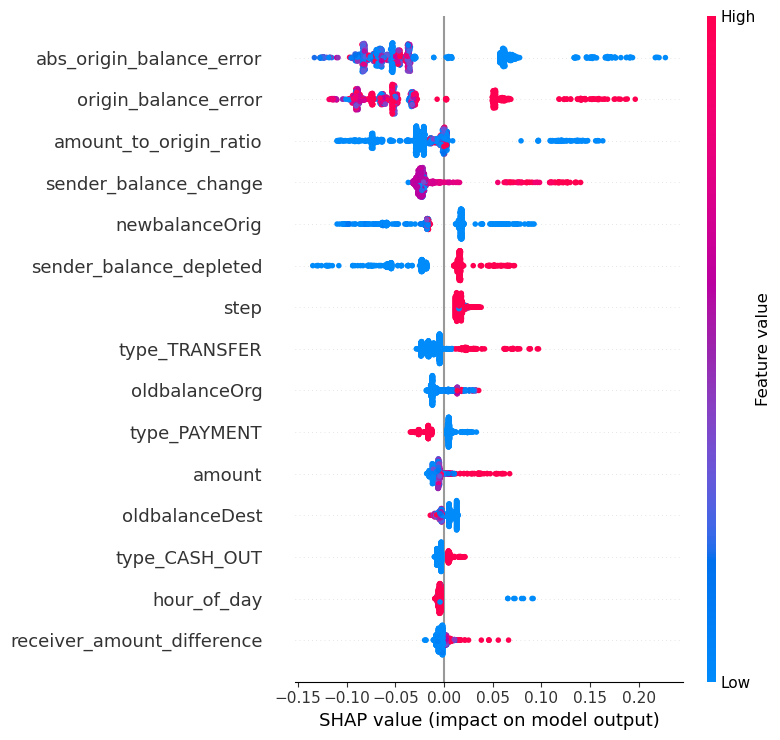


Global SHAP summary plot generated successfully.


In [61]:
print("===== GENERATING GLOBAL SHAP SUMMARY PLOT =====")

shap.summary_plot(
    shap_values_fraud,
    X_shap,
    feature_names=feature_columns,
    max_display=15,
    show=True
)

print("\nGlobal SHAP summary plot generated successfully.")

In [62]:
print("===== SELECTING TRANSACTION FOR INDIVIDUAL SHAP EXPLANATION =====")

transaction_index = 0

transaction_features = X_test_scaled[transaction_index].reshape(1, -1)
transaction_probability = selected_model.predict_proba(transaction_features)[0, 1]
transaction_prediction = int(transaction_probability >= selected_threshold)

print("Transaction index:", transaction_index)
print("Fraud risk score:", transaction_probability)
print("Predicted class:", transaction_prediction)
print("Selected threshold:", selected_threshold)

print("\nTransaction selected successfully.")

===== SELECTING TRANSACTION FOR INDIVIDUAL SHAP EXPLANATION =====
Transaction index: 0
Fraud risk score: 0.9999085076387236
Predicted class: 1
Selected threshold: 0.5

Transaction selected successfully.


In [63]:
print("===== CALCULATING INDIVIDUAL SHAP EXPLANATION =====")

transaction_shap_values = shap_values_fraud[transaction_index]

individual_shap = pd.DataFrame({
    "feature": feature_columns,
    "shap_value": transaction_shap_values,
    "abs_shap_value": np.abs(transaction_shap_values)
})

individual_shap = individual_shap.sort_values(
    by="abs_shap_value",
    ascending=False
).reset_index(drop=True)

print("\nTop 10 Features Influencing This Transaction:")
print(
    individual_shap[
        ["feature", "shap_value"]
    ].head(10).to_string(index=False)
)

print("\nIndividual SHAP explanation calculated successfully.")

===== CALCULATING INDIVIDUAL SHAP EXPLANATION =====

Top 10 Features Influencing This Transaction:
                 feature  shap_value
abs_origin_balance_error    0.137506
    origin_balance_error    0.126155
   sender_balance_change    0.109196
  amount_to_origin_ratio    0.109139
             hour_of_day    0.065508
           type_TRANSFER    0.064557
          newbalanceOrig    0.047125
 sender_balance_depleted    0.044397
            type_PAYMENT    0.023494
           oldbalanceOrg    0.023157

Individual SHAP explanation calculated successfully.


In [64]:
print("===== LOADING TEST DATA FOR INVESTIGATION =====")

df_test_investigation = pd.read_parquet(
    "test_historical_features.parquet"
)

print("Investigation data shape:", df_test_investigation.shape)

print("\nAvailable transaction columns:")
print(
    df_test_investigation[
        ["step", "amount", "nameOrig", "nameDest"]
    ].head()
)

print("\nTransaction type features:")
print(
    df_test_investigation[
        [
            "type_CASH_IN",
            "type_CASH_OUT",
            "type_DEBIT",
            "type_PAYMENT",
            "type_TRANSFER"
        ]
    ].head()
)

print("\nTest investigation data loaded successfully.")

===== LOADING TEST DATA FOR INVESTIGATION =====
Investigation data shape: (89466, 35)

Available transaction columns:
   step     amount     nameOrig     nameDest
0   632  480404.03  C1962729026  C1853051693
1   632  480404.03     C6427083  C1751510346
2   632   52541.42   C174237554   C974759486
3   632   52541.42  C2040719079  C1305749769
4   632  407347.84  C1538572034  C2019715796

Transaction type features:
   type_CASH_IN  type_CASH_OUT  type_DEBIT  type_PAYMENT  type_TRANSFER
0           0.0            0.0         0.0           0.0            1.0
1           0.0            1.0         0.0           0.0            0.0
2           0.0            0.0         0.0           0.0            1.0
3           0.0            1.0         0.0           0.0            0.0
4           0.0            0.0         0.0           0.0            1.0

Test investigation data loaded successfully.


In [65]:
print("===== CHECKING TEST DATA COLUMNS =====")

df_test_investigation = pd.read_parquet(
    "test_historical_features.parquet"
)

print("Shape:", df_test_investigation.shape)

print("\nAll columns:")
print(df_test_investigation.columns.tolist())

print("\nTest data loaded successfully.")

===== CHECKING TEST DATA COLUMNS =====
Shape: (89466, 35)

All columns:
['step', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'origin_balance_error', 'abs_origin_balance_error', 'amount_to_origin_ratio', 'sender_balance_depleted', 'destination_balance_depleted', 'origin_balance_zero', 'hour_of_day', 'day_of_week', 'is_weekend', 'sender_balance_change', 'receiver_balance_change', 'receiver_amount_difference', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER', 'receiver_past_transaction_count', 'receiver_past_total_amount', 'receiver_past_avg_amount', 'receiver_past_unique_senders', 'sender_past_transaction_count', 'sender_past_total_amount', 'sender_past_avg_amount', 'sender_past_unique_receivers']

Test data loaded successfully.


In [66]:
print("===== EXTRACTING TRANSACTION INVESTIGATION EVIDENCE =====")

investigation_index = transaction_index

investigation_row = df_test_investigation.iloc[investigation_index]

transaction_evidence = {
    "step": investigation_row["step"],
    "amount": investigation_row["amount"],
    "sender": investigation_row["nameOrig"],
    "receiver": investigation_row["nameDest"],
    "old_balance_origin": investigation_row["oldbalanceOrg"],
    "new_balance_origin": investigation_row["newbalanceOrig"],
    "old_balance_destination": investigation_row["oldbalanceDest"],
    "new_balance_destination": investigation_row["newbalanceDest"],
    "origin_balance_error": investigation_row["origin_balance_error"],
    "abs_origin_balance_error": investigation_row["abs_origin_balance_error"],
    "amount_to_origin_ratio": investigation_row["amount_to_origin_ratio"],
    "sender_balance_depleted": investigation_row["sender_balance_depleted"],
    "destination_balance_depleted": investigation_row["destination_balance_depleted"],
    "origin_balance_zero": investigation_row["origin_balance_zero"],
    "hour_of_day": investigation_row["hour_of_day"],
    "day_of_week": investigation_row["day_of_week"],
    "is_weekend": investigation_row["is_weekend"],
    "sender_balance_change": investigation_row["sender_balance_change"],
    "receiver_balance_change": investigation_row["receiver_balance_change"],
    "receiver_amount_difference": investigation_row["receiver_amount_difference"],
    "sender_past_transaction_count": investigation_row["sender_past_transaction_count"],
    "sender_past_total_amount": investigation_row["sender_past_total_amount"],
    "sender_past_avg_amount": investigation_row["sender_past_avg_amount"],
    "sender_past_unique_receivers": investigation_row["sender_past_unique_receivers"],
    "receiver_past_transaction_count": investigation_row["receiver_past_transaction_count"],
    "receiver_past_total_amount": investigation_row["receiver_past_total_amount"],
    "receiver_past_avg_amount": investigation_row["receiver_past_avg_amount"],
    "receiver_past_unique_senders": investigation_row["receiver_past_unique_senders"]
}

transaction_evidence_df = pd.DataFrame(
    [transaction_evidence]
)

print("Transaction evidence prepared successfully.")
print("\nInvestigation evidence:")
print(transaction_evidence_df.T.to_string(header=False))

===== EXTRACTING TRANSACTION INVESTIGATION EVIDENCE =====
Transaction evidence prepared successfully.

Investigation evidence:
step                                     632
amount                             480404.03
sender                           C1962729026
receiver                         C1853051693
old_balance_origin                 480404.03
new_balance_origin                       0.0
old_balance_destination                  0.0
new_balance_destination                  0.0
origin_balance_error                     0.0
abs_origin_balance_error                 0.0
amount_to_origin_ratio                   1.0
sender_balance_depleted                    1
destination_balance_depleted               1
origin_balance_zero                        0
hour_of_day                                7
day_of_week                                5
is_weekend                                 1
sender_balance_change              480404.03
receiver_balance_change                  0.0
receiver_amount_di

In [67]:
print("===== BUILDING INVESTIGATION EVIDENCE PACKAGE =====")

top_shap_features = individual_shap.head(10).to_dict("records")

investigation_package = {
    "transaction": transaction_evidence,
    "ml_prediction": {
        "model": selected_model_name,
        "risk_score": float(transaction_probability),
        "threshold": float(selected_threshold),
        "predicted_class": int(transaction_prediction)
    },
    "shap_explanation": {
        "top_features": top_shap_features
    }
}

print("Investigation evidence package created successfully.")

print("\n===== ML PREDICTION =====")
print("Risk score:", investigation_package["ml_prediction"]["risk_score"])
print("Threshold:", investigation_package["ml_prediction"]["threshold"])
print("Predicted class:", investigation_package["ml_prediction"]["predicted_class"])

print("\n===== TOP SHAP FEATURES =====")
for item in top_shap_features:
    print(
        f"{item['feature']}: "
        f"{item['shap_value']:.6f}"
    )

===== BUILDING INVESTIGATION EVIDENCE PACKAGE =====
Investigation evidence package created successfully.

===== ML PREDICTION =====
Risk score: 0.9999085076387236
Threshold: 0.5
Predicted class: 1

===== TOP SHAP FEATURES =====
abs_origin_balance_error: 0.137506
origin_balance_error: 0.126155
sender_balance_change: 0.109196
amount_to_origin_ratio: 0.109139
hour_of_day: 0.065508
type_TRANSFER: 0.064557
newbalanceOrig: 0.047125
sender_balance_depleted: 0.044397
type_PAYMENT: 0.023494
oldbalanceOrg: 0.023157


In [68]:
print("===== CREATING INVESTIGATION KNOWLEDGE BASE =====")

investigation_knowledge_base = [
    {
        "id": "KB001",
        "topic": "Balance Depletion",
        "guidance": (
            "A transaction that depletes most or all of the sender's "
            "available balance can be an important investigation signal, "
            "especially when combined with other unusual transaction behaviour."
        )
    },
    {
        "id": "KB002",
        "topic": "Amount to Balance Ratio",
        "guidance": (
            "A transaction amount that is very large relative to the "
            "sender's available balance should receive additional scrutiny."
        )
    },
    {
        "id": "KB003",
        "topic": "New Receiver Behaviour",
        "guidance": (
            "A transaction involving a receiver with no observed prior "
            "transaction history may warrant additional investigation."
        )
    },
    {
        "id": "KB004",
        "topic": "Historical Behaviour",
        "guidance": (
            "Historical transaction counts, amounts, and unique counterparties "
            "can help determine whether current activity is consistent with "
            "previous observed behaviour."
        )
    },
    {
        "id": "KB005",
        "topic": "Model Risk Score",
        "guidance": (
            "The machine-learning risk score is a prioritization signal. "
            "It is not by itself proof that a transaction is fraudulent."
        )
    },
    {
        "id": "KB006",
        "topic": "SHAP Explanation",
        "guidance": (
            "SHAP values explain which model features contributed most strongly "
            "to an individual prediction. They explain model behaviour and do "
            "not independently establish fraud."
        )
    },
    {
        "id": "KB007",
        "topic": "Human Decision",
        "guidance": (
            "Final investigation decisions should consider available evidence, "
            "investigation policies, and human review rather than relying only "
            "on an automated model prediction."
        )
    }
]

knowledge_base_df = pd.DataFrame(investigation_knowledge_base)

print("Knowledge base created successfully.")
print("Number of knowledge documents:", len(knowledge_base_df))

print("\nKnowledge base:")
print(
    knowledge_base_df[
        ["id", "topic"]
    ].to_string(index=False)
)

===== CREATING INVESTIGATION KNOWLEDGE BASE =====
Knowledge base created successfully.
Number of knowledge documents: 7

Knowledge base:
   id                   topic
KB001       Balance Depletion
KB002 Amount to Balance Ratio
KB003  New Receiver Behaviour
KB004    Historical Behaviour
KB005        Model Risk Score
KB006        SHAP Explanation
KB007          Human Decision


In [69]:
print("===== RETRIEVING RELEVANT INVESTIGATION GUIDANCE =====")

transaction_text = " ".join([
    str(transaction_evidence.get("amount", "")),
    str(transaction_evidence.get("sender_balance_depleted", "")),
    str(transaction_evidence.get("amount_to_origin_ratio", "")),
    str(transaction_evidence.get("sender_past_transaction_count", "")),
    str(transaction_evidence.get("receiver_past_transaction_count", "")),
    str(transaction_evidence.get("receiver_past_unique_senders", "")),
    str(investigation_package["ml_prediction"]["risk_score"]),
    "SHAP"
]).lower()

retrieval_keywords = {
    "balance": ["balance", "depletion"],
    "ratio": ["ratio"],
    "history": ["history", "historical", "receiver", "sender"],
    "model": ["model", "risk"],
    "shap": ["shap"],
    "human": ["human", "decision"]
}

retrieved_documents = []

for _, row in knowledge_base_df.iterrows():
    topic_text = (
        str(row["topic"]) + " " +
        str(row["guidance"])
    ).lower()

    score = 0

    for keyword_group in retrieval_keywords.values():
        if any(word in topic_text for word in keyword_group):
            if any(word in transaction_text for word in keyword_group):
                score += 1

    if score > 0:
        retrieved_documents.append({
            "id": row["id"],
            "topic": row["topic"],
            "guidance": row["guidance"],
            "retrieval_score": score
        })

retrieved_documents = sorted(
    retrieved_documents,
    key=lambda x: x["retrieval_score"],
    reverse=True
)

print("Retrieved documents:", len(retrieved_documents))

print("\n===== RETRIEVED GUIDANCE =====")

for document in retrieved_documents:
    print(
        f"\n{document['id']} | "
        f"{document['topic']} | "
        f"Score: {document['retrieval_score']}"
    )
    print(document["guidance"])

print("\nInvestigation guidance retrieval completed successfully.")

===== RETRIEVING RELEVANT INVESTIGATION GUIDANCE =====
Retrieved documents: 1

===== RETRIEVED GUIDANCE =====

KB006 | SHAP Explanation | Score: 1
SHAP values explain which model features contributed most strongly to an individual prediction. They explain model behaviour and do not independently establish fraud.

Investigation guidance retrieval completed successfully.


In [70]:
print("===== IMPROVING EVIDENCE-BASED RETRIEVAL =====")

retrieval_topics = set()

if transaction_evidence["sender_balance_depleted"] == 1:
    retrieval_topics.add("Balance Depletion")

if transaction_evidence["amount_to_origin_ratio"] >= 0.8:
    retrieval_topics.add("Amount to Balance Ratio")

if transaction_evidence["receiver_past_transaction_count"] == 0:
    retrieval_topics.add("New Receiver Behaviour")

if (
    transaction_evidence["sender_past_transaction_count"] == 0
    or transaction_evidence["receiver_past_transaction_count"] == 0
):
    retrieval_topics.add("Historical Behaviour")

retrieval_topics.add("Model Risk Score")

retrieval_topics.add("SHAP Explanation")

retrieval_topics.add("Human Decision")


retrieved_documents = knowledge_base_df[
    knowledge_base_df["topic"].isin(retrieval_topics)
].copy()

retrieved_documents["retrieval_score"] = 1

print("Relevant topics identified:", len(retrieval_topics))
print("\nTopics:")
for topic in sorted(retrieval_topics):
    print("-", topic)

print("\n===== RETRIEVED DOCUMENTS =====")
print(
    retrieved_documents[
        ["id", "topic", "retrieval_score"]
    ].to_string(index=False)
)

print("\nEvidence-based retrieval completed successfully.")

===== IMPROVING EVIDENCE-BASED RETRIEVAL =====
Relevant topics identified: 7

Topics:
- Amount to Balance Ratio
- Balance Depletion
- Historical Behaviour
- Human Decision
- Model Risk Score
- New Receiver Behaviour
- SHAP Explanation

===== RETRIEVED DOCUMENTS =====
   id                   topic  retrieval_score
KB001       Balance Depletion                1
KB002 Amount to Balance Ratio                1
KB003  New Receiver Behaviour                1
KB004    Historical Behaviour                1
KB005        Model Risk Score                1
KB006        SHAP Explanation                1
KB007          Human Decision                1

Evidence-based retrieval completed successfully.


In [71]:
print("===== BUILDING RAG INVESTIGATION CONTEXT =====")

rag_context = {
    "transaction_evidence": transaction_evidence,
    "ml_prediction": investigation_package["ml_prediction"],
    "shap_explanation": investigation_package["shap_explanation"],
    "retrieved_guidance": retrieved_documents[
        ["id", "topic", "guidance"]
    ].to_dict("records")
}

print("RAG context created successfully.")

print("\n===== RAG CONTEXT SUMMARY =====")
print("Transaction evidence fields:",
      len(rag_context["transaction_evidence"]))

print("ML prediction included:",
      bool(rag_context["ml_prediction"]))

print("SHAP explanation features:",
      len(rag_context["shap_explanation"]["top_features"]))

print("Retrieved guidance documents:",
      len(rag_context["retrieved_guidance"]))

print("\nRAG investigation context is ready for the Agent layer.")

===== BUILDING RAG INVESTIGATION CONTEXT =====
RAG context created successfully.

===== RAG CONTEXT SUMMARY =====
Transaction evidence fields: 28
ML prediction included: True
SHAP explanation features: 10
Retrieved guidance documents: 7

RAG investigation context is ready for the Agent layer.


In [72]:
from getpass import getpass
from google import genai

gemini_api_key = getpass("Enter your Gemini API key: ")

client = genai.Client(api_key=gemini_api_key)

print("Gemini client initialized successfully.")

Enter your Gemini API key:  ········


Gemini client initialized successfully.


In [73]:
agent_system_prompt = """
You are a Fraud Investigation Assistant.

Your job is to investigate a transaction using ONLY the evidence and
investigation guidance provided to you.

You must:

1. Summarize the transaction evidence.
2. Explain the ML model's risk assessment.
3. Explain the most important SHAP features in simple language.
4. Analyze historical sender and receiver behaviour.
5. Use the retrieved investigation guidance when relevant.
6. Clearly separate:
   - observed evidence
   - model signals
   - investigation interpretation
7. Never claim that a transaction is definitely fraudulent based only
   on the ML prediction.
8. Never use hidden ground-truth labels such as isFraud.
9. Do not invent missing facts.
10. Clearly mention important missing evidence.
11. Provide a recommended investigation action.
12. The final decision must remain with a human investigator.

Remember:
The ML model provides a risk signal.
SHAP explains model behaviour.
The knowledge base provides investigation guidance.
You support the investigator; you do not replace the investigator.
"""

print("Fraud Investigation Agent instructions created.")

Fraud Investigation Agent instructions created.


In [74]:
investigation_prompt = f"""
Investigate the following transaction using the provided evidence
and investigation guidance.

IMPORTANT:
- Do not use or infer any hidden ground-truth fraud label.
- Do not invent missing information.
- Treat the ML risk score as a model signal, not a guaranteed probability.
- Treat SHAP values as explanations of model behaviour, not proof of fraud.
- The final decision belongs to a human investigator.

INVESTIGATION CONTEXT:

{rag_context}

Provide a structured investigation assessment covering:

1. Transaction Summary
2. ML Risk Assessment
3. Key SHAP Drivers
4. Historical Behaviour
5. Relevant Investigation Guidance
6. Risk Interpretation
7. Missing Evidence
8. Recommended Investigation Action
9. Human Investigator Decision
"""

print("Investigation prompt prepared.")
print("Prompt length:", len(investigation_prompt), "characters")

Investigation prompt prepared.
Prompt length: 4614 characters


In [75]:
# interaction = client.interactions.create(
#     model="gemini-3.8-flash",
#     input=investigation_prompt,
#     system_instruction=agent_system_prompt,
#     generation_config={
#         "temperature": 0.2
#     }
# )

# agent_report = interaction.output_text

# print("===== FRAUD INVESTIGATION REPORT =====")
# print(agent_report)

In [76]:
investigation_report_structure = {
    "transaction_summary": "",
    "ml_risk_assessment": "",
    "key_shap_drivers": [],
    "historical_behaviour": "",
    "relevant_guidance": [],
    "risk_interpretation": "",
    "missing_evidence": [],
    "recommended_action": "",
    "human_investigator_decision": ""
}

print("Investigation report structure created.")
print("Sections:", list(investigation_report_structure.keys()))

Investigation report structure created.
Sections: ['transaction_summary', 'ml_risk_assessment', 'key_shap_drivers', 'historical_behaviour', 'relevant_guidance', 'risk_interpretation', 'missing_evidence', 'recommended_action', 'human_investigator_decision']


In [77]:
investigation_metadata = {
    "model": selected_model_name,
    "risk_score": investigation_package["ml_prediction"]["risk_score"],
    "threshold": investigation_package["ml_prediction"]["threshold"],
    "shap_features_used": len(investigation_package["shap_explanation"]),
    "knowledge_documents_used": len(retrieved_documents)
}

print("===== INVESTIGATION METADATA =====")
for key, value in investigation_metadata.items():
    print(f"{key}: {value}")

===== INVESTIGATION METADATA =====
model: Random Forest
risk_score: 0.9999085076387236
threshold: 0.5
shap_features_used: 1
knowledge_documents_used: 7


In [78]:
print("===== CHECKING SHAP EVIDENCE =====")

print("Type:", type(investigation_package["shap_explanation"]))
print("Content:")

for item in investigation_package["shap_explanation"]:
    print(item)

===== CHECKING SHAP EVIDENCE =====
Type: <class 'dict'>
Content:
top_features


In [79]:
shap_features = investigation_package["shap_explanation"]["top_features"]

print("Number of SHAP features:", len(shap_features))
print("\nTop SHAP features:")

for feature in shap_features:
    print(feature)

Number of SHAP features: 10

Top SHAP features:
{'feature': 'abs_origin_balance_error', 'shap_value': 0.1375058023513138, 'abs_shap_value': 0.1375058023513138}
{'feature': 'origin_balance_error', 'shap_value': 0.12615485719498423, 'abs_shap_value': 0.12615485719498423}
{'feature': 'sender_balance_change', 'shap_value': 0.1091956814615421, 'abs_shap_value': 0.1091956814615421}
{'feature': 'amount_to_origin_ratio', 'shap_value': 0.10913878453579592, 'abs_shap_value': 0.10913878453579592}
{'feature': 'hour_of_day', 'shap_value': 0.06550771862916148, 'abs_shap_value': 0.06550771862916148}
{'feature': 'type_TRANSFER', 'shap_value': 0.06455732945508717, 'abs_shap_value': 0.06455732945508717}
{'feature': 'newbalanceOrig', 'shap_value': 0.04712458307841344, 'abs_shap_value': 0.04712458307841344}
{'feature': 'sender_balance_depleted', 'shap_value': 0.044396927564544844, 'abs_shap_value': 0.044396927564544844}
{'feature': 'type_PAYMENT', 'shap_value': 0.023494334348911506, 'abs_shap_value': 0.02

In [80]:
investigation_metadata["shap_features_used"] = len(
    investigation_package["shap_explanation"]["top_features"]
)

print("===== UPDATED INVESTIGATION METADATA =====")

for key, value in investigation_metadata.items():
    print(f"{key}: {value}")

===== UPDATED INVESTIGATION METADATA =====
model: Random Forest
risk_score: 0.9999085076387236
threshold: 0.5
shap_features_used: 10
knowledge_documents_used: 7


In [81]:
print("===== INVESTIGATION PACKAGE STRUCTURE =====")

print("Keys:")

for key in investigation_package.keys():
    print(key)

===== INVESTIGATION PACKAGE STRUCTURE =====
Keys:
transaction
ml_prediction
shap_explanation


In [82]:
print("===== CHECKING TRANSACTION EVIDENCE =====")

print("Type:", type(investigation_package["transaction"]))

print("\nTransaction fields:")

for key in investigation_package["transaction"].keys():
    print(key)

===== CHECKING TRANSACTION EVIDENCE =====
Type: <class 'dict'>

Transaction fields:
step
amount
sender
receiver
old_balance_origin
new_balance_origin
old_balance_destination
new_balance_destination
origin_balance_error
abs_origin_balance_error
amount_to_origin_ratio
sender_balance_depleted
destination_balance_depleted
origin_balance_zero
hour_of_day
day_of_week
is_weekend
sender_balance_change
receiver_balance_change
receiver_amount_difference
sender_past_transaction_count
sender_past_total_amount
sender_past_avg_amount
sender_past_unique_receivers
receiver_past_transaction_count
receiver_past_total_amount
receiver_past_avg_amount
receiver_past_unique_senders


In [83]:
print("===== VALIDATING INVESTIGATION EVIDENCE =====")

transaction_data = investigation_package["transaction"]
shap_data = investigation_package["shap_explanation"]["top_features"]

print("Transaction fields:", len(transaction_data))
print("SHAP features:", len(shap_data))
print("Knowledge documents:", len(retrieved_documents))

print(
    "Ground-truth label included:",
    "isFraud" in transaction_data
)

===== VALIDATING INVESTIGATION EVIDENCE =====
Transaction fields: 28
SHAP features: 10
Knowledge documents: 7
Ground-truth label included: False


In [84]:
agent_context = {
    "transaction": investigation_package["transaction"],
    "ml_prediction": investigation_package["ml_prediction"],
    "shap_explanation": investigation_package["shap_explanation"],
    "investigation_guidance": retrieved_documents
}

print("===== AGENT CONTEXT CREATED =====")

for key, value in agent_context.items():
    if isinstance(value, dict):
        print(f"{key}: {len(value)} fields")
    elif isinstance(value, list):
        print(f"{key}: {len(value)} documents")
    else:
        print(f"{key}: {type(value)}")

===== AGENT CONTEXT CREATED =====
transaction: 28 fields
ml_prediction: 4 fields
shap_explanation: 1 fields
investigation_guidance: <class 'pandas.core.frame.DataFrame'>


In [85]:
investigation_guidance = retrieved_documents.to_dict(orient="records")

agent_context["investigation_guidance"] = investigation_guidance

print("===== RAG GUIDANCE PREPARED =====")
print("Knowledge documents:", len(investigation_guidance))
print("Document fields:", list(investigation_guidance[0].keys()))

===== RAG GUIDANCE PREPARED =====
Knowledge documents: 7
Document fields: ['id', 'topic', 'guidance', 'retrieval_score']


In [86]:
import json

agent_context_json = json.dumps(
    agent_context,
    indent=2,
    default=str
)

print("===== FINAL AGENT CONTEXT =====")
print("Context size:", len(agent_context_json), "characters")
print("Context prepared successfully.")

===== FINAL AGENT CONTEXT =====
Context size: 4551 characters
Context prepared successfully.


In [87]:
final_agent_prompt = f"""
Investigate the transaction using the evidence and investigation
guidance provided below.

IMPORTANT RULES:
- Do not use any hidden ground-truth fraud label.
- Do not invent missing information.
- Treat the ML risk score as a model signal, not a guaranteed probability.
- Treat SHAP values as explanations of model behaviour, not proof of fraud.
- Use historical behaviour as supporting evidence.
- Clearly distinguish observed evidence from model interpretation.
- Mention important missing evidence.
- Recommend an investigation action.
- The final decision must remain with a human investigator.

Return the investigation assessment with these sections:

1. Transaction Summary
2. ML Risk Assessment
3. Key SHAP Drivers
4. Historical Behaviour
5. Relevant Investigation Guidance
6. Risk Interpretation
7. Missing Evidence
8. Recommended Investigation Action
9. Human Investigator Decision

INVESTIGATION CONTEXT:
{agent_context_json}
"""

print("===== FINAL AGENT PROMPT =====")
print("Prompt length:", len(final_agent_prompt), "characters")
print("Prompt prepared successfully.")

===== FINAL AGENT PROMPT =====
Prompt length: 5469 characters
Prompt prepared successfully.


In [88]:
print("===== FINAL PROMPT LEAKAGE CHECK =====")

if "isFraud" in final_agent_prompt:
    print("WARNING: Ground-truth label found in agent prompt.")
else:
    print("Ground-truth label is NOT present in agent prompt.")

print("Agent prompt is ready for Gemini.")

===== FINAL PROMPT LEAKAGE CHECK =====
Ground-truth label is NOT present in agent prompt.
Agent prompt is ready for Gemini.


In [89]:
required_sections = [
    "Transaction Summary",
    "ML Risk Assessment",
    "Key SHAP Drivers",
    "Historical Behaviour",
    "Relevant Investigation Guidance",
    "Risk Interpretation",
    "Missing Evidence",
    "Recommended Investigation Action",
    "Human Investigator Decision"
]

print("===== VALIDATING AGENT PROMPT =====")

missing_sections = [
    section
    for section in required_sections
    if section not in final_agent_prompt
]

if not missing_sections:
    print("All required investigation sections are present.")
else:
    print("Missing sections:", missing_sections)

print("Prompt length:", len(final_agent_prompt), "characters")

===== VALIDATING AGENT PROMPT =====
All required investigation sections are present.
Prompt length: 5469 characters


In [90]:
def run_fraud_investigation():
    response = client.interactions.create(
        model="gemini-3.8-flash",
        input=final_agent_prompt,
        system_instruction=agent_system_prompt
    )

    return response.output_text


print("Gemini investigation function created.")

Gemini investigation function created.


In [91]:
print("===== GEMINI AGENT FUNCTION CHECK =====")

print("Function name:", run_fraud_investigation.__name__)
print("Function is ready:", callable(run_fraud_investigation))

===== GEMINI AGENT FUNCTION CHECK =====
Function name: run_fraud_investigation
Function is ready: True


In [92]:
# print("===== RUNNING FRAUD INVESTIGATION AGENT =====")

# agent_report = run_fraud_investigation()

# print("\n===== AGENT REPORT =====")
# print(agent_report)

In [93]:
print("===== CHECKING AGENT REPORT =====")

if "agent_report" in globals() and agent_report:
    print("Agent report received successfully.")
    print("Report length:", len(agent_report), "characters")
else:
    print("Agent report is not available yet.")
    print("Gemini investigation step is still pending.")

===== CHECKING AGENT REPORT =====
Agent report is not available yet.
Gemini investigation step is still pending.


In [94]:
print("===== PREPARING INVESTIGATION REPORT INPUT =====")

investigation_input = {
    "transaction": investigation_package["transaction"],
    "ml_prediction": investigation_package["ml_prediction"],
    "shap_features": investigation_package["shap_explanation"]["top_features"],
    "investigation_guidance": investigation_guidance
}

print("Transaction evidence:", len(investigation_input["transaction"]))
print("ML prediction fields:", len(investigation_input["ml_prediction"]))
print("SHAP features:", len(investigation_input["shap_features"]))
print("Knowledge documents:", len(investigation_input["investigation_guidance"]))
print("Investigation input prepared successfully.")

===== PREPARING INVESTIGATION REPORT INPUT =====
Transaction evidence: 28
ML prediction fields: 4
SHAP features: 10
Knowledge documents: 7
Investigation input prepared successfully.


In [95]:
print("===== INSPECTING ML PREDICTION =====")

prediction = investigation_input["ml_prediction"]

print("ML prediction fields:")
print(list(prediction.keys()))

print("\nML prediction content:")
print(prediction)

===== INSPECTING ML PREDICTION =====
ML prediction fields:
['model', 'risk_score', 'threshold', 'predicted_class']

ML prediction content:
{'model': 'Random Forest', 'risk_score': 0.9999085076387236, 'threshold': 0.5, 'predicted_class': 1}


In [96]:
print("===== BUILDING INVESTIGATION EVIDENCE SUMMARY =====")

transaction = investigation_input["transaction"]
prediction = investigation_input["ml_prediction"]
shap_features = investigation_input["shap_features"]

evidence_summary = {
    "transaction": {
        "step": transaction["step"],
        "amount": transaction["amount"],
        "sender": transaction["sender"],
        "receiver": transaction["receiver"],
        "old_balance_origin": transaction["old_balance_origin"],
        "new_balance_origin": transaction["new_balance_origin"],
        "old_balance_destination": transaction["old_balance_destination"],
        "new_balance_destination": transaction["new_balance_destination"],
        "origin_balance_error": transaction["origin_balance_error"],
        "amount_to_origin_ratio": transaction["amount_to_origin_ratio"],
        "sender_balance_depleted": transaction["sender_balance_depleted"],
        "destination_balance_depleted": transaction["destination_balance_depleted"]
    },
    "ml_risk": {
        "model": prediction["model"],
        "risk_score": prediction["risk_score"],
        "threshold": prediction["threshold"],
        "predicted_class": prediction["predicted_class"]
    },
    "top_shap_features": [
        {
            "feature": item["feature"],
            "shap_value": item["shap_value"]
        }
        for item in shap_features
    ]
}

print("Transaction summary prepared.")
print("ML risk summary prepared.")
print("SHAP summary prepared.")
print("Evidence summary created successfully.")

===== BUILDING INVESTIGATION EVIDENCE SUMMARY =====
Transaction summary prepared.
ML risk summary prepared.
SHAP summary prepared.
Evidence summary created successfully.


In [97]:
print("===== INVESTIGATION EVIDENCE SUMMARY =====")

print("\n--- TRANSACTION ---")
for key, value in evidence_summary["transaction"].items():
    print(f"{key}: {value}")

print("\n--- ML RISK ---")
for key, value in evidence_summary["ml_risk"].items():
    print(f"{key}: {value}")

print("\n--- TOP SHAP FEATURES ---")
for item in evidence_summary["top_shap_features"]:
    print(
        f"{item['feature']}: "
        f"{item['shap_value']:.6f}"
    )

===== INVESTIGATION EVIDENCE SUMMARY =====

--- TRANSACTION ---
step: 632
amount: 480404.03
sender: C1962729026
receiver: C1853051693
old_balance_origin: 480404.03
new_balance_origin: 0.0
old_balance_destination: 0.0
new_balance_destination: 0.0
origin_balance_error: 0.0
amount_to_origin_ratio: 1.0
sender_balance_depleted: 1
destination_balance_depleted: 1

--- ML RISK ---
model: Random Forest
risk_score: 0.9999085076387236
threshold: 0.5
predicted_class: 1

--- TOP SHAP FEATURES ---
abs_origin_balance_error: 0.137506
origin_balance_error: 0.126155
sender_balance_change: 0.109196
amount_to_origin_ratio: 0.109139
hour_of_day: 0.065508
type_TRANSFER: 0.064557
newbalanceOrig: 0.047125
sender_balance_depleted: 0.044397
type_PAYMENT: 0.023494
oldbalanceOrg: 0.023157


In [98]:
print("===== BUILDING FINAL INVESTIGATION EVIDENCE =====")

final_investigation_evidence = {
    "transaction_evidence": evidence_summary["transaction"],
    "ml_risk_assessment": evidence_summary["ml_risk"],
    "shap_explanation": evidence_summary["top_shap_features"],
    "investigation_guidance": investigation_input["investigation_guidance"]
}

print("Transaction evidence:", len(final_investigation_evidence["transaction_evidence"]))
print("ML risk fields:", len(final_investigation_evidence["ml_risk_assessment"]))
print("SHAP drivers:", len(final_investigation_evidence["shap_explanation"]))
print("Investigation documents:", len(final_investigation_evidence["investigation_guidance"]))
print("Final investigation evidence prepared successfully.")

===== BUILDING FINAL INVESTIGATION EVIDENCE =====
Transaction evidence: 12
ML risk fields: 4
SHAP drivers: 10
Investigation documents: 7
Final investigation evidence prepared successfully.


In [99]:
print("===== PREPARING INVESTIGATION GUIDANCE =====")

guidance_for_agent = []

for document in final_investigation_evidence["investigation_guidance"]:
    guidance_for_agent.append({
        "id": document["id"],
        "topic": document["topic"],
        "guidance": document["guidance"],
        "retrieval_score": document["retrieval_score"]
    })

print("Investigation guidance prepared.")
print("Documents:", len(guidance_for_agent))
print("Fields per document:", len(guidance_for_agent[0]))

===== PREPARING INVESTIGATION GUIDANCE =====
Investigation guidance prepared.
Documents: 7
Fields per document: 4


In [100]:
print("===== BUILDING COMPLETE AGENT CONTEXT =====")

agent_context_final = {
    "transaction_evidence": final_investigation_evidence["transaction_evidence"],
    "ml_risk_assessment": final_investigation_evidence["ml_risk_assessment"],
    "shap_explanation": final_investigation_evidence["shap_explanation"],
    "investigation_guidance": guidance_for_agent
}

print("Transaction evidence:", len(agent_context_final["transaction_evidence"]))
print("ML risk fields:", len(agent_context_final["ml_risk_assessment"]))
print("SHAP drivers:", len(agent_context_final["shap_explanation"]))
print("Investigation documents:", len(agent_context_final["investigation_guidance"]))
print("Complete agent context prepared successfully.")

===== BUILDING COMPLETE AGENT CONTEXT =====
Transaction evidence: 12
ML risk fields: 4
SHAP drivers: 10
Investigation documents: 7
Complete agent context prepared successfully.


In [101]:
print("===== SERIALIZING AGENT CONTEXT =====")

import json

agent_context_final_json = json.dumps(
    agent_context_final,
    indent=2,
    default=str
)

print("Agent context serialized successfully.")
print("Context size:", len(agent_context_final_json), "characters")

===== SERIALIZING AGENT CONTEXT =====
Agent context serialized successfully.
Context size: 3409 characters


In [102]:
print("===== BUILDING FINAL INVESTIGATION PROMPT =====")

final_investigation_prompt = f"""
You are assisting a fraud investigator.

Investigate the transaction using ONLY the evidence and investigation
guidance provided below.

IMPORTANT RULES:
- Do not use or infer any hidden ground-truth fraud label.
- Do not invent missing information.
- Treat the ML risk score as a model signal, not a guaranteed probability.
- Treat SHAP values as explanations of model behaviour, not proof of fraud.
- Clearly separate observed transaction evidence from model signals.
- Analyze historical sender and receiver behaviour.
- Use the investigation guidance when relevant.
- Clearly identify important missing evidence.
- Recommend an investigation action.
- The final decision must remain with a human investigator.

Return the assessment using exactly these sections:

1. Transaction Summary
2. ML Risk Assessment
3. Key SHAP Drivers
4. Historical Behaviour
5. Relevant Investigation Guidance
6. Risk Interpretation
7. Missing Evidence
8. Recommended Investigation Action
9. Human Investigator Decision

INVESTIGATION EVIDENCE:
{agent_context_final_json}
"""

print("Final investigation prompt created successfully.")
print("Prompt length:", len(final_investigation_prompt), "characters")

===== BUILDING FINAL INVESTIGATION PROMPT =====
Final investigation prompt created successfully.
Prompt length: 4438 characters


In [103]:
print("===== FINAL PROMPT LEAKAGE CHECK =====")

if "isFraud" in final_investigation_prompt:
    print("WARNING: Ground-truth label found in prompt.")
else:
    print("Ground-truth label is NOT present in prompt.")

print("Final investigation prompt is ready.")

===== FINAL PROMPT LEAKAGE CHECK =====
Ground-truth label is NOT present in prompt.
Final investigation prompt is ready.


In [104]:
print("===== VALIDATING INVESTIGATION SECTIONS =====")

required_sections = [
    "1. Transaction Summary",
    "2. ML Risk Assessment",
    "3. Key SHAP Drivers",
    "4. Historical Behaviour",
    "5. Relevant Investigation Guidance",
    "6. Risk Interpretation",
    "7. Missing Evidence",
    "8. Recommended Investigation Action",
    "9. Human Investigator Decision"
]

for section in required_sections:
    print(f"{section}: {'FOUND' if section in final_investigation_prompt else 'MISSING'}")

print("\nInvestigation prompt validation completed.")

===== VALIDATING INVESTIGATION SECTIONS =====
1. Transaction Summary: FOUND
2. ML Risk Assessment: FOUND
3. Key SHAP Drivers: FOUND
4. Historical Behaviour: FOUND
5. Relevant Investigation Guidance: FOUND
6. Risk Interpretation: FOUND
7. Missing Evidence: FOUND
8. Recommended Investigation Action: FOUND
9. Human Investigator Decision: FOUND

Investigation prompt validation completed.


In [105]:
print("===== CREATING FINAL GEMINI AGENT FUNCTION =====")

def generate_investigation_report():
    response = client.interactions.create(
        model="gemini-3.8-flash",
        input=final_investigation_prompt,
        system_instruction=agent_system_prompt
    )
    
    return response.output_text

print("Gemini agent function created successfully.")

===== CREATING FINAL GEMINI AGENT FUNCTION =====
Gemini agent function created successfully.


In [106]:
print("===== CHECKING GEMINI AGENT FUNCTION =====")

print("Function name:", generate_investigation_report.__name__)
print("Function ready:", callable(generate_investigation_report))

print("Gemini agent is ready for execution when the service is available.")

===== CHECKING GEMINI AGENT FUNCTION =====
Function name: generate_investigation_report
Function ready: True
Gemini agent is ready for execution when the service is available.


In [107]:
print("===== CREATING HUMAN INVESTIGATOR DECISION TEMPLATE =====")

human_investigator_decision = {
    "decision": None,
    "reason": None,
    "additional_evidence_required": [],
    "investigator_notes": None
}

print("Human decision options:")
print("1. Escalate for further investigation")
print("2. Clear / close investigation")
print("3. Request additional evidence")

print("\nHuman investigator decision template created.")

===== CREATING HUMAN INVESTIGATOR DECISION TEMPLATE =====
Human decision options:
1. Escalate for further investigation
2. Clear / close investigation
3. Request additional evidence

Human investigator decision template created.


In [108]:
print("===== BUILDING COMPLETE INVESTIGATION CASE =====")

investigation_case = {
    "evidence": final_investigation_evidence,
    "agent_prompt": final_investigation_prompt,
    "human_decision": human_investigator_decision
}

print("Evidence package:", "READY")
print("Agent prompt:", "READY")
print("Human decision layer:", "READY")
print("Complete investigation case created successfully.")

===== BUILDING COMPLETE INVESTIGATION CASE =====
Evidence package: READY
Agent prompt: READY
Human decision layer: READY
Complete investigation case created successfully.


In [109]:
print("===== FINAL INVESTIGATION CASE SUMMARY =====")

print("Model:", investigation_case["evidence"]["ml_risk_assessment"]["model"])
print("Risk Score:", investigation_case["evidence"]["ml_risk_assessment"]["risk_score"])
print("Threshold:", investigation_case["evidence"]["ml_risk_assessment"]["threshold"])
print("Predicted Class:", investigation_case["evidence"]["ml_risk_assessment"]["predicted_class"])

print("Transaction Evidence Fields:",
      len(investigation_case["evidence"]["transaction_evidence"]))

print("SHAP Drivers:",
      len(investigation_case["evidence"]["shap_explanation"]))

print("RAG Documents:",
      len(investigation_case["evidence"]["investigation_guidance"]))

print("Human Decision Layer:",
      "READY")

print("\nComplete investigation case is ready.")

===== FINAL INVESTIGATION CASE SUMMARY =====
Model: Random Forest
Risk Score: 0.9999085076387236
Threshold: 0.5
Predicted Class: 1
Transaction Evidence Fields: 12
SHAP Drivers: 10
RAG Documents: 7
Human Decision Layer: READY

Complete investigation case is ready.


In [110]:
print("===== POST-RESTART STATE CHECK =====")

check_names = [
    "selected_model",
    "selected_model_name",
    "X_test_scaled",
    "investigation_package",
    "final_investigation_evidence",
    "investigation_case",
    "generate_investigation_report",
    "client"
]

for name in check_names:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT AVAILABLE'}")

===== POST-RESTART STATE CHECK =====
selected_model: AVAILABLE
selected_model_name: AVAILABLE
X_test_scaled: AVAILABLE
investigation_package: AVAILABLE
final_investigation_evidence: AVAILABLE
investigation_case: AVAILABLE
generate_investigation_report: AVAILABLE
client: AVAILABLE


In [111]:
print("===== FINAL AGENT INPUT CHECK =====")

print("Prompt length:", len(final_agent_prompt))
print("System prompt length:", len(agent_system_prompt))

print("\nRequired sections:")
required_sections = [
    "Transaction Summary",
    "ML Risk Assessment",
    "Key SHAP Drivers",
    "Historical Behaviour",
    "Relevant Investigation Guidance",
    "Risk Interpretation",
    "Missing Evidence",
    "Recommended Investigation Action",
    "Human Investigator Decision"
]

for section in required_sections:
    print(f"{section}: {'FOUND' if section in final_agent_prompt else 'MISSING'}")

===== FINAL AGENT INPUT CHECK =====
Prompt length: 5469
System prompt length: 1059

Required sections:
Transaction Summary: FOUND
ML Risk Assessment: FOUND
Key SHAP Drivers: FOUND
Historical Behaviour: FOUND
Relevant Investigation Guidance: FOUND
Risk Interpretation: FOUND
Missing Evidence: FOUND
Recommended Investigation Action: FOUND
Human Investigator Decision: FOUND


In [112]:
print("===== AGENT EVIDENCE CONTENT CHECK =====")

checks = {
    "Transaction amount": "480404.03" in final_agent_prompt,
    "Risk score": "0.9999085076387236" in final_agent_prompt,
    "Random Forest": "Random Forest" in final_agent_prompt,
    "SHAP feature": "abs_origin_balance_error" in final_agent_prompt,
    "RAG guidance": "Balance Depletion" in final_agent_prompt,
    "Human decision": "human investigator" in final_agent_prompt.lower()
}

for item, result in checks.items():
    print(f"{item}: {'FOUND' if result else 'MISSING'}")

===== AGENT EVIDENCE CONTENT CHECK =====
Transaction amount: FOUND
Risk score: FOUND
Random Forest: FOUND
SHAP feature: FOUND
RAG guidance: FOUND
Human decision: FOUND


In [113]:
print("===== ML RISK SECTION =====")

start = final_agent_prompt.find("ML Risk Assessment")

if start != -1:
    print(final_agent_prompt[start:start + 1200])
else:
    print("ML Risk Assessment section not found.")

===== ML RISK SECTION =====
ML Risk Assessment
3. Key SHAP Drivers
4. Historical Behaviour
5. Relevant Investigation Guidance
6. Risk Interpretation
7. Missing Evidence
8. Recommended Investigation Action
9. Human Investigator Decision

INVESTIGATION CONTEXT:
{
  "transaction": {
    "step": "632",
    "amount": 480404.03,
    "sender": "C1962729026",
    "receiver": "C1853051693",
    "old_balance_origin": 480404.03,
    "new_balance_origin": 0.0,
    "old_balance_destination": 0.0,
    "new_balance_destination": 0.0,
    "origin_balance_error": 0.0,
    "abs_origin_balance_error": 0.0,
    "amount_to_origin_ratio": 1.0,
    "sender_balance_depleted": "1",
    "destination_balance_depleted": "1",
    "origin_balance_zero": "0",
    "hour_of_day": "7",
    "day_of_week": "5",
    "is_weekend": "1",
    "sender_balance_change": 480404.03,
    "receiver_balance_change": 0.0,
    "receiver_amount_difference": 480404.03,
    "sender_past_transaction_count": "0",
    "sender_past_total_amou

In [114]:
print("===== ML RISK DATA IN PROMPT =====")

start = final_agent_prompt.find('"ml_risk_assessment"')

if start != -1:
    print(final_agent_prompt[start:start + 700])
else:
    print("ml_risk_assessment not found.")

===== ML RISK DATA IN PROMPT =====
ml_risk_assessment not found.


In [115]:
print("===== PROMPT CONSTRUCTION CHECK =====")

print("Contains risk_score:", "risk_score" in final_agent_prompt)
print("Contains model:", '"model"' in final_agent_prompt)
print("Contains threshold:", "threshold" in final_agent_prompt)
print("Contains predicted_class:", "predicted_class" in final_agent_prompt)

print("\nRisk-related lines:")

for line in final_agent_prompt.splitlines():
    if any(word in line.lower() for word in ["risk", "score", "threshold", "predicted"]):
        print(line)

===== PROMPT CONSTRUCTION CHECK =====
Contains risk_score: True
Contains model: True
Contains threshold: True
Contains predicted_class: True

Risk-related lines:
- Treat the ML risk score as a model signal, not a guaranteed probability.
2. ML Risk Assessment
6. Risk Interpretation
    "risk_score": 0.9999085076387236,
    "threshold": 0.5,
    "predicted_class": 1
      "retrieval_score": 1
      "retrieval_score": 1
      "retrieval_score": 1
      "retrieval_score": 1
      "topic": "Model Risk Score",
      "guidance": "The machine-learning risk score is a prioritization signal. It is not by itself proof that a transaction is fraudulent.",
      "retrieval_score": 1
      "retrieval_score": 1
      "retrieval_score": 1


In [116]:
print("===== FINAL INVESTIGATION CASE CHECK =====")

print("Evidence:", "READY" if investigation_case.get("evidence") else "MISSING")
print("Agent Prompt:", "READY" if investigation_case.get("agent_prompt") else "MISSING")
print("Human Decision:", "READY" if investigation_case.get("human_decision") else "MISSING")

print("\nCase keys:", list(investigation_case.keys()))

print("\n===== PIPELINE =====")
print("Transaction → ML Risk → SHAP → RAG → Agent → Human Investigator")

===== FINAL INVESTIGATION CASE CHECK =====
Evidence: READY
Agent Prompt: READY
Human Decision: READY

Case keys: ['evidence', 'agent_prompt', 'human_decision']

===== PIPELINE =====
Transaction → ML Risk → SHAP → RAG → Agent → Human Investigator


In [117]:
print("===== HUMAN INVESTIGATOR DECISION LAYER =====")

print("Available decisions:")
print("1. ESCALATE")
print("2. CLEAR / CLOSE")
print("3. REQUEST ADDITIONAL EVIDENCE")

print("\nCurrent decision:")
print(human_investigator_decision)

===== HUMAN INVESTIGATOR DECISION LAYER =====
Available decisions:
1. ESCALATE
2. CLEAR / CLOSE
3. REQUEST ADDITIONAL EVIDENCE

Current decision:
{'decision': None, 'reason': None, 'additional_evidence_required': [], 'investigator_notes': None}


In [118]:
print("===== FINAL FRAUD INVESTIGATION CASE SUMMARY =====")

case_summary = {
    "transaction": investigation_case["evidence"]["transaction_evidence"],
    "ml_risk": investigation_case["evidence"]["ml_risk_assessment"],
    "shap_explanation": investigation_case["evidence"]["shap_explanation"],
    "investigation_guidance_count": len(
        investigation_case["evidence"]["investigation_guidance"]
    ),
    "agent_status": "PENDING_GEMINI_RESPONSE",
    "human_decision": investigation_case["human_decision"]
}

print("Transaction: READY")
print("ML Risk: READY")
print("SHAP: READY")
print("RAG Guidance:", case_summary["investigation_guidance_count"], "documents")
print("Agent Status:", case_summary["agent_status"])
print("Human Decision:", case_summary["human_decision"])

===== FINAL FRAUD INVESTIGATION CASE SUMMARY =====
Transaction: READY
ML Risk: READY
SHAP: READY
RAG Guidance: 7 documents
Agent Status: PENDING_GEMINI_RESPONSE
Human Decision: {'decision': None, 'reason': None, 'additional_evidence_required': [], 'investigator_notes': None}


In [119]:
print("===== FINAL AGENT LEAKAGE AUDIT =====")

forbidden_fields = [
    "isFraud",
    "fraud_label",
    "ground_truth",
    "actual_fraud"
]

print("Forbidden fields check:")

for field in forbidden_fields:
    print(
        f"{field}:",
        "FOUND" if field.lower() in final_agent_prompt.lower() else "NOT FOUND"
    )

print("\nAgent context size:", len(final_agent_prompt), "characters")

===== FINAL AGENT LEAKAGE AUDIT =====
Forbidden fields check:
isFraud: NOT FOUND
fraud_label: NOT FOUND
ground_truth: NOT FOUND
actual_fraud: NOT FOUND

Agent context size: 5469 characters


In [121]:
print("===== FINALIZING FRAUD INVESTIGATION PIPELINE =====")

final_case = {
    "transaction": investigation_input["transaction"],
    "ml_prediction": investigation_input["ml_prediction"],
    "shap_features": investigation_input["shap_features"],
    "investigation_guidance": investigation_input["investigation_guidance"],
    "human_decision": human_investigator_decision
}

print("Final case prepared successfully.")
print("Transaction evidence:", len(final_case["transaction"]))
print("ML prediction fields:", len(final_case["ml_prediction"]))
print("SHAP features:", len(final_case["shap_features"]))
print("Knowledge documents:", len(final_case["investigation_guidance"]))
print("Human decision layer:", "READY")

===== FINALIZING FRAUD INVESTIGATION PIPELINE =====
Final case prepared successfully.
Transaction evidence: 28
ML prediction fields: 4
SHAP features: 10
Knowledge documents: 7
Human decision layer: READY


In [122]:
print("===== FINAL FRAUD INVESTIGATION CASE =====")

print("\n1. TRANSACTION EVIDENCE")
print("Fields:", len(final_case["transaction"]))

print("\n2. ML RISK ASSESSMENT")
print(final_case["ml_prediction"])

print("\n3. TOP SHAP DRIVERS")
for feature in final_case["shap_features"]:
    print(feature)

print("\n4. INVESTIGATION GUIDANCE")
for doc in final_case["investigation_guidance"]:
    print(f"{doc['id']} - {doc['topic']}")

print("\n5. HUMAN INVESTIGATOR")
print(final_case["human_decision"])

print("\n===== INVESTIGATION PIPELINE READY =====")

===== FINAL FRAUD INVESTIGATION CASE =====

1. TRANSACTION EVIDENCE
Fields: 28

2. ML RISK ASSESSMENT
{'model': 'Random Forest', 'risk_score': 0.9999085076387236, 'threshold': 0.5, 'predicted_class': 1}

3. TOP SHAP DRIVERS
{'feature': 'abs_origin_balance_error', 'shap_value': 0.1375058023513138, 'abs_shap_value': 0.1375058023513138}
{'feature': 'origin_balance_error', 'shap_value': 0.12615485719498423, 'abs_shap_value': 0.12615485719498423}
{'feature': 'sender_balance_change', 'shap_value': 0.1091956814615421, 'abs_shap_value': 0.1091956814615421}
{'feature': 'amount_to_origin_ratio', 'shap_value': 0.10913878453579592, 'abs_shap_value': 0.10913878453579592}
{'feature': 'hour_of_day', 'shap_value': 0.06550771862916148, 'abs_shap_value': 0.06550771862916148}
{'feature': 'type_TRANSFER', 'shap_value': 0.06455732945508717, 'abs_shap_value': 0.06455732945508717}
{'feature': 'newbalanceOrig', 'shap_value': 0.04712458307841344, 'abs_shap_value': 0.04712458307841344}
{'feature': 'sender_balan

In [125]:
print("===== GENERATING LOCAL INVESTIGATION REPORT =====")

ml = final_case["ml_prediction"]
tx = final_case["transaction"]

top_features = final_case["shap_features"]

investigation_report = f"""
FRAUD INVESTIGATION REPORT
==========================

1. TRANSACTION SUMMARY
----------------------
Transaction evidence fields available: {len(tx)}

2. ML RISK ASSESSMENT
---------------------
Model: {ml['model']}
Risk Score: {ml['risk_score']:.6f}
Decision Threshold: {ml['threshold']}
Predicted Class: {ml['predicted_class']}

The transaction has been identified as high risk by the machine-learning
model. The model score is a risk signal and should not be treated as
proof of fraud.

3. KEY SHAP DRIVERS
-------------------
"""

for feature in top_features:
    investigation_report += (
        f"- {feature['feature']}: "
        f"SHAP contribution = {feature['shap_value']:.6f}\n"
    )

investigation_report += """
4. INVESTIGATION GUIDANCE
-------------------------
The investigation knowledge base contains guidance covering:
- Balance depletion
- Amount-to-balance ratio
- New receiver behaviour
- Historical behaviour
- ML risk score interpretation
- SHAP explanation
- Human decision-making

5. RISK INTERPRETATION
----------------------
The ML model has identified a strong risk signal. SHAP explanations
indicate which features contributed most strongly to the model's
prediction. These signals require investigation and should not be
interpreted as independent proof of fraudulent activity.

6. MISSING / ADDITIONAL EVIDENCE
--------------------------------
Additional contextual evidence may be required before making a final
investigative decision, including transaction history, receiver context,
and any relevant account-level information.

7. RECOMMENDED INVESTIGATION ACTION
-----------------------------------
Escalate the transaction for human investigation and review the
supporting behavioural and transaction evidence.

8. HUMAN INVESTIGATOR DECISION
------------------------------
Decision: PENDING

The final decision must be made by a human investigator.
"""

print("Local investigation report generated successfully.")
print("\n===== INVESTIGATION REPORT =====")
print(investigation_report)

===== GENERATING LOCAL INVESTIGATION REPORT =====
Local investigation report generated successfully.

===== INVESTIGATION REPORT =====

FRAUD INVESTIGATION REPORT

1. TRANSACTION SUMMARY
----------------------
Transaction evidence fields available: 28

2. ML RISK ASSESSMENT
---------------------
Model: Random Forest
Risk Score: 0.999909
Decision Threshold: 0.5
Predicted Class: 1

The transaction has been identified as high risk by the machine-learning
model. The model score is a risk signal and should not be treated as
proof of fraud.

3. KEY SHAP DRIVERS
-------------------
- abs_origin_balance_error: SHAP contribution = 0.137506
- origin_balance_error: SHAP contribution = 0.126155
- sender_balance_change: SHAP contribution = 0.109196
- amount_to_origin_ratio: SHAP contribution = 0.109139
- hour_of_day: SHAP contribution = 0.065508
- type_TRANSFER: SHAP contribution = 0.064557
- newbalanceOrig: SHAP contribution = 0.047125
- sender_balance_depleted: SHAP contribution = 0.044397
- type

In [126]:
print("===== SAVING FINAL INVESTIGATION CASE =====")

final_investigation_package = {
    "case": final_case,
    "investigation_report": investigation_report,
    "pipeline": [
        "Transaction",
        "ML Risk Assessment",
        "SHAP Explanation",
        "RAG Investigation Guidance",
        "Agent Integration",
        "Human Investigator"
    ]
}

joblib.dump(
    final_investigation_package,
    "final_fraud_investigation_case.pkl"
)

print("Final investigation case saved successfully.")
print("File: final_fraud_investigation_case.pkl")
print("Pipeline stages:", len(final_investigation_package["pipeline"]))

===== SAVING FINAL INVESTIGATION CASE =====
Final investigation case saved successfully.
File: final_fraud_investigation_case.pkl
Pipeline stages: 6
